# Detecting Re-injury Risk in NBA Players with an EWMA-CUSUM Control Chart

This notebook contains the full analysis pipeline for monitoring NBA players' on-court performance after they return from injury, using a lower-sided EWMA-CUSUM control chart to flag performance declines that may precede a second injury.

**Data.** Regular-season player and team box scores for the 2020-21 through 2024-25 seasons (hoopR `seasons = 2021:2025`, where a season is labelled by the calendar year in which it ends), loaded with the [`hoopR`](https://hoopr.sportsdataverse.org/) package. Injury absences are identified from the `did_not_play` / `reason` fields of the player box scores.

**Performance metrics monitored.** PIE, Usage Rate, a simplified box plus-minus (BPM), and Net Rating (Dean Oliver offensive/defensive ratings).

**Pipeline overview**

| Part | Steps | Contents |
|---|---|---|
| 1 | 1–14 | Data preparation: load box scores, identify qualifying injury stints, return-to-play and subsequent re-injury, and compute per-game metrics |
| 2 | 15–19 | Control-chart machinery: EWMA-CUSUM statistic, parameter grid, player-specific empirical-Bayes (shrinkage) baselines, chart runners and confusion-matrix summaries |
| 3 | 20–26 | Evaluation: baselines fit on training seasons only, block-bootstrap check for autocorrelation, (λ, h) selected on training seasons, and a single application of the frozen model to the held-out season |
| 4 | 27–28 | ROC curve and AUC across a wide (λ, h) grid (training seasons) |
| 5 | 29–31 | Figures: parameter-grid heatmaps (overall and by injury area) and an example control chart |
| 6 | 32–41 | Descriptive and supplementary statistics |

**In-control baseline.** Each player's in-control mean is a credibility-weighted blend of their own pre-injury mean and the league grand mean (empirical-Bayes shrinkage, with the shrinkage weight *k* estimated by one-way random-effects ANOVA method of moments); the in-control SD is the pooled within-player SD.

**Running the notebook.** Run all cells top to bottom with an R kernel (e.g. Google Colab with the R runtime, or Jupyter with IRkernel). The first run downloads several seasons of box scores and the bootstrap/grid steps take a while. Figures are written as PNG files to the working directory.

## Setup

In [1]:
required_pkgs <- c("tidyverse", "hoopR", "patchwork")
missing_pkgs  <- setdiff(required_pkgs, rownames(installed.packages()))
if (length(missing_pkgs) > 0) install.packages(missing_pkgs)

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘iterators’, ‘foreach’, ‘shape’, ‘RcppEigen’, ‘snakecase’, ‘glmnet’, ‘janitor’, ‘progressr’, ‘RcppParallel’, ‘stringdist’




In [2]:
library(tidyverse)
library(hoopR)
library(patchwork)

# join_by() inequality joins, pick() and reframe() require dplyr >= 1.1.0
stopifnot(packageVersion("dplyr") >= "1.1.0")

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


### Parameters and lookup tables

In [3]:
seasons <- 2021:2025      # hoopR season = calendar year in which the season ends

bootstrap_seed <- 2026    # seed for the block bootstrap (Step 23)

non_inj_reasons <- c(
  "ASTHMA ATTACK", "COACH'S DECISION", "DENTAL PAIN",
  "DID NOT DRESS", "FAMILY MATTERS", "FLU", "FLU LIKE SYMPTOMS",
  "FOOD POISONING", "GASTROENTERITIS", "HEALTH & SAFETY PROTOCOLS",
  "ILLNESS", "MIGRAINE", "MONONUCLEOSIS", "NON-COVID ILLNESS",
  "ORAL SURGERY", "RESPIRATORY", "SICK", "SINUSES", "SORE THROAT",
  "STOMACH", "STOMACH ILLNESS", "STOMACH VIRUS",
  "UPPER RESPIRATORY INFECTION", "VIRUS", "SUSPENDED BY LEAGUE",
  "TRADED",
  "G-LEAGUE ASSIGNMENT", "NOT WITH TEAM",
  "NOT WITH TEAM - G LEAGUE ASSIGNMENT", "PERSONAL",
  "PERSONAL REASONS", "REST", "RETURN TO COMPETITION CONDITIONING",
  "TRADE PENDING", "TWO-WAY CONTRACT",
  "RETURN TO COMPETITION RECONDITIONING",
  "SURGERY REHAB",
  "SUSPENDED BY TEAM"
)

lower_extremity_keywords <- c(
  "ACHILLES", "ANKLE", "CALF", "FOOT", "HAMSTRING", "HIP",
  "KNEE", "LEG", "PATELLAR", "PLANTAR", "QUAD", "QUADRICEP",
  "SHIN", "THIGH", "TOE", "GROIN", "GLUTE", "GLUTEAL",
  "ACL", "MCL", "PCL", "MENISCUS", "ADDUCTOR", "ABDUCTOR",
  "SOLEUS", "TIBIAL", "TIBIA", "FIBULA", "HEEL", "PELVIC",
  "PELVIS", "TAILBONE", "PATELLA", "GREAT TOE"
)

upper_extremity_keywords <- c(
  "ELBOW", "FINGER", "FOREARM", "HAND", "SHOULDER", "THUMB",
  "WRIST", "BICEP", "TRICEP", "ROTATOR CUFF", "COLLARBONE",
  "CLAVICLE", "AC JOINT", "LABRUM", "ARM", "UCL", "ULNAR"
)

core_keywords <- c(
  "ABDOMEN", "ABDOMINAL", "BACK", "CORE", "HERNIA", "LUMBAR",
  "NECK", "RIB", "RIBS", "SPINE", "THORACIC", "OBLIQUE",
  "STERNUM", "CHEST", "CERVICAL", "WHIPLASH"
)

head_keywords <- c(
  "HEAD", "CONCUSSION", "FACE", "FACIAL", "NOSE", "NASAL",
  "EYE", "SINUS"
)

clean_reason <- function(reason) {
  reason |>
    str_to_upper() |>
    str_trim() |>
    str_remove("^(LEFT|RIGHT|BILATERAL)\\s+") |>
    str_remove(paste0(
      "^(SORE|STRAINED|SPRAINED|TORN|TIGHT|TIGHTNESS|INFLAMED|",
      "BRUISED|BROKEN|FRACTURED|DISLOCATED|SWOLLEN|SURGERY|",
      "SORENESS|TENDINITIS|STRESS FRACTURE|BONE BRUISE)\\s+"
    ))
}

# Body-region classification; checked in order (first match wins)
classify_injury <- function(reason_cleaned) {
  case_when(
    str_detect(reason_cleaned, paste(head_keywords,            collapse = "|")) ~ "Head",
    str_detect(reason_cleaned, paste(core_keywords,            collapse = "|")) ~ "Core",
    str_detect(reason_cleaned, paste(upper_extremity_keywords, collapse = "|")) ~ "Upper Extremity",
    str_detect(reason_cleaned, paste(lower_extremity_keywords, collapse = "|")) ~ "Lower Extremity",
    TRUE ~ "Other"
  )
}

## Part 1 — Data preparation

### Step 1. Load box scores (regular season only)

In [4]:
team_box_raw <- load_nba_team_box(seasons = seasons) |>
  filter(season_type == 2) |>
  select(
    game_id, game_date, team_display_name, team_score,
    field_goals_made, field_goals_attempted,
    three_point_field_goals_made,
    free_throws_made, free_throws_attempted,
    offensive_rebounds, defensive_rebounds, total_rebounds,
    assists, steals, blocks, turnovers, fouls
  ) |>
  rename(Team = team_display_name) |>
  mutate(
    game_date = as.Date(game_date),
    Season    = lubridate::year(game_date) +
                if_else(lubridate::month(game_date) >= 10, 1, 0)
  )

player_box_raw <- load_nba_player_box(seasons = seasons) |>
  filter(season_type == 2) |>
  mutate(
    game_date = as.Date(game_date),
    Team      = paste(team_location, team_name)
  ) |>
  rename(Season = season)

### Step 2. Game number within each team-season

In [5]:
team_box <- team_box_raw |>
  group_by(Team, Season) |>
  arrange(game_date, .by_group = TRUE) |>
  mutate(game_number = row_number()) |>
  ungroup() |>
  filter(game_number <= 82)

### Step 3. Team minutes
Computed from the raw player box (before any player filtering) so team totals are complete.

In [6]:
team_minutes <- player_box_raw |>
  filter(did_not_play == FALSE, active == TRUE, minutes > 0) |>
  mutate(minutes = as.numeric(minutes)) |>
  group_by(game_id, Team) |>
  summarise(t_minutes = sum(minutes, na.rm = TRUE), .groups = "drop")

### Step 4. Team game log
Team box-score stats joined with opponent stats and team/opponent minutes.

In [7]:
# Self-join on game_id pairs each team with both teams in the game
# (hence many-to-many); the Team != Opp_Team filter keeps the opponent row.
opponent_stats <- team_box |>
  inner_join(
    team_box |>
      select(
        game_id,
        Opp_Team = Team,
        Opp_PTS  = team_score,
        Opp_FGM  = field_goals_made,
        Opp_FGA  = field_goals_attempted,
        Opp_FTM  = free_throws_made,
        Opp_FTA  = free_throws_attempted,
        Opp_ORB  = offensive_rebounds,
        Opp_DRB  = defensive_rebounds,
        Opp_TRB  = total_rebounds,
        Opp_AST  = assists,
        Opp_STL  = steals,
        Opp_BLK  = blocks,
        Opp_TOV  = turnovers,
        Opp_PF   = fouls
      ),
    by = "game_id",
    relationship = "many-to-many"
  ) |>
  filter(Team != Opp_Team) |>
  select(game_id, Team, starts_with("Opp_"))

opponent_minutes <- team_minutes |>
  rename(Opp_Team = Team, Opp_t_minutes = t_minutes) |>
  left_join(
    team_box |> select(game_id, Team) |>
      inner_join(team_box |> select(game_id, Opp_Team = Team),
                 by = "game_id", relationship = "many-to-many") |>
      filter(Team != Opp_Team),
    by = c("game_id", "Opp_Team")
  ) |>
  select(game_id, Team, Opp_t_minutes) |>
  distinct()

team_gamelog <- team_box |>
  rename(
    t_pts  = team_score,
    t_fgm  = field_goals_made,
    t_fga  = field_goals_attempted,
    t_3pm  = three_point_field_goals_made,
    t_ftm  = free_throws_made,
    t_fta  = free_throws_attempted,
    t_oreb = offensive_rebounds,
    t_dreb = defensive_rebounds,
    t_treb = total_rebounds,
    t_ast  = assists,
    t_stl  = steals,
    t_blk  = blocks,
    t_to   = turnovers,
    t_pf   = fouls
  ) |>
  left_join(team_minutes,     by = c("game_id", "Team")) |>
  left_join(opponent_stats,   by = c("game_id", "Team")) |>
  left_join(opponent_minutes, by = c("game_id", "Team")) |>
  select(-game_number)

### Step 5. Restrict to players with a single team per season, and attach game number

In [8]:
single_team_players <- player_box_raw |>
  distinct(athlete_id, Season, Team) |>
  group_by(athlete_id, Season) |>
  filter(n() == 1) |>
  ungroup()

player_box <- player_box_raw |>
  semi_join(single_team_players, by = c("athlete_id", "Season"))

player_full <- player_box |>
  left_join(
    team_box |> select(game_id, Team, Season, game_number),
    by = c("game_id", "Team", "Season")
  )

### Step 6. Injury-related DNPs and injury classification

In [9]:
injury_data <- player_full |>
  filter(
    did_not_play == TRUE,
    !(reason %in% non_inj_reasons)
  ) |>
  mutate(
    reason_upper   = str_to_upper(str_trim(reason)),
    reason_cleaned = clean_reason(reason_upper),
    injury_type    = classify_injury(reason_cleaned)
  ) |>
  arrange(athlete_id, game_date)

### Step 7. Injury stints
Consecutive injury DNPs separated by no more than 5 team games are grouped into one stint.

In [10]:
get_mode <- function(x) {
  x <- x[!is.na(x)]
  if (length(x) == 0) return(NA_character_)
  names(sort(table(x), decreasing = TRUE))[1]
}

injury_stints <- injury_data |>
  group_by(athlete_id, Season) |>
  arrange(game_number, .by_group = TRUE) |>
  mutate(
    missed_gap   = game_number - lag(game_number),
    new_stint    = if_else(is.na(missed_gap) | missed_gap > 5, 1, 0),
    Injury_Stint = cumsum(new_stint)
  ) |>
  ungroup() |>
  group_by(athlete_id, Season, Injury_Stint) |>
  summarise(
    first_game_missed     = min(game_number),
    last_game_missed      = max(game_number),
    games_missed_in_stint = n(),
    stint_span            = last_game_missed - first_game_missed + 1,
    injury_type           = get_mode(injury_type),
    primary_reason        = get_mode(reason_upper),
    .groups = "drop"
  )

### Step 8. Return game for each stint

In [11]:
played_games <- player_full |>
  filter(did_not_play == FALSE, active == TRUE, minutes > 0) |>
  select(athlete_id, Season, game_number)

injury_stints_with_return <- injury_stints |>
  left_join(played_games, by = c("athlete_id", "Season")) |>
  filter(game_number > last_game_missed) |>
  group_by(athlete_id, Season, Injury_Stint) |>
  filter(game_number == min(game_number)) |>
  rename(game_returned = game_number) |>
  ungroup() |>
  mutate(
    actual_games_missed = game_returned - first_game_missed,
    games_until_return  = game_returned - last_game_missed
  )

Warning message in left_join(injury_stints, played_games, by = c("athlete_id", "Season")):
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 27968 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”


### Step 9. Qualifying-stint filters

In [12]:
qualifying_stints <- injury_stints_with_return |>
  filter(
    stint_span         >= 2,
    games_until_return <= 4
  )

### Step 10. First qualifying stint per player-season and the next injury

The subsequent-injury lookup uses an inequality join (`join_by(..., Injury_Stint < next_stint)`). A plain equi-join on `athlete_id` + `Season` would match each stint to itself, and players with no later injury would then be dropped entirely rather than retained with `had_second_injury = FALSE`. With the inequality join, a player with no later stint keeps a single row with `next_stint = NA`.

In [13]:
first_stints <- qualifying_stints |>
  group_by(athlete_id, Season) |>
  slice_min(Injury_Stint, n = 1) |>
  ungroup()

all_stints_lookup <- injury_stints_with_return |>
  select(athlete_id, Season, Injury_Stint, first_game_missed)

qualifying_with_next_injury <- first_stints |>
  left_join(
    all_stints_lookup |>
      rename(next_stint             = Injury_Stint,
             next_first_game_missed = first_game_missed),
    by = join_by(athlete_id, Season, Injury_Stint < next_stint)
  ) |>
  group_by(athlete_id, Season, Injury_Stint) |>
  arrange(next_stint, .by_group = TRUE) |>   # NA sorts last; real matches ascending
  slice(1) |>                                # soonest subsequent stint, or the lone NA row
  ungroup() |>
  rename(
    second_injury_stint      = next_stint,
    second_injury_first_game = next_first_game_missed
  ) |>
  mutate(
    had_second_injury   = !is.na(second_injury_stint),
    analysis_window_end = if_else(had_second_injury,
                                  second_injury_first_game - 1L, 82L)
  )

# Class balance check: both TRUE and FALSE should be present
qualifying_with_next_injury |> count(had_second_injury)

had_second_injury,n
<lgl>,<int>
FALSE,137
TRUE,72


### Step 11. Helper functions for per-game metrics

* `compute_box_metrics()` adds PIE, Usage Rate and BPM. It expects the player box columns, the matching `team_gamelog` columns, and `lg_ts` (league true-shooting % for the season, from `league_ts_by_season`, Step 12).
* `compute_oliver_ratings()` adds ORtg, DRtg and NetRtg (Dean Oliver / Basketball-Reference formulas). It expects the player box columns, the `team_gamelog` columns (`t_*`, `Opp_*`, `t_minutes`, `Opp_t_minutes`) and `minutes`.

Both are shared by the league reference table (Step 12), the post-return window (Steps 13–14) and the pre-injury panel (Step 17), so every part of the pipeline uses identical metric definitions.

In [14]:
compute_box_metrics <- function(df) {
  df |>
    mutate(
      p_pie_num = points + field_goals_made + free_throws_made -
                  field_goals_attempted - free_throws_attempted +
                  defensive_rebounds + 0.5 * offensive_rebounds +
                  assists + steals + 0.5 * blocks - fouls - turnovers,
      t_pie_den = t_pts + t_fgm + t_ftm - t_fga - t_fta +
                  t_dreb + 0.5 * t_oreb + t_ast + t_stl + 0.5 * t_blk - t_pf - t_to,
      PIE       = p_pie_num / t_pie_den,

      Usage_Rate = (field_goals_attempted + 0.44 * free_throws_attempted + turnovers) /
                   (t_fga + 0.44 * t_fta + t_to),

      ts_pct = if_else(
        field_goals_attempted + free_throws_attempted == 0, lg_ts,
        points / (2 * (field_goals_attempted + 0.44 * free_throws_attempted))
      ),
      ast_rate  = if_else(minutes == 0, 0, assists / minutes),
      oreb_rate = if_else(minutes == 0, 0, offensive_rebounds / minutes),
      dreb_rate = if_else(minutes == 0, 0, defensive_rebounds / minutes),
      BPM = (ts_pct - lg_ts) * 40 +
            ast_rate * 3 -
            oreb_rate * 1.5 +
            dreb_rate * 2 -
            (turnovers / pmax(minutes, 1)) * 3
    )
}

compute_oliver_ratings <- function(df) {
  df |>
    mutate(
      Team_Scoring_Poss = t_fgm +
        (1 - (1 - if_else(t_fta == 0, 0, t_ftm / t_fta))^2) * t_fta * 0.4,

      Team_Play_pct = if_else(
        (t_fga + t_fta * 0.4 + t_to) == 0, 0,
        Team_Scoring_Poss / (t_fga + t_fta * 0.4 + t_to)
      ),

      Team_ORB_pct = if_else(
        (t_oreb + (Opp_TRB - Opp_ORB)) == 0, 0,
        t_oreb / (t_oreb + (Opp_TRB - Opp_ORB))
      ),

      Team_ORB_Weight = if_else(
        ((1 - Team_ORB_pct) * Team_Play_pct + Team_ORB_pct * (1 - Team_Play_pct)) == 0, 0,
        ((1 - Team_ORB_pct) * Team_Play_pct) /
          ((1 - Team_ORB_pct) * Team_Play_pct + Team_ORB_pct * (1 - Team_Play_pct))
      ),

      qAST = if_else(
        t_minutes == 0 | (t_fgm - field_goals_made) == 0, 0,
        ((minutes / (t_minutes / 5)) *
           (1.14 * ((t_ast - assists) / t_fgm))) +
          ((((t_ast / t_minutes) * minutes * 5 - assists) /
              ((t_fgm / t_minutes) * minutes * 5 - field_goals_made)) *
             (1 - (minutes / (t_minutes / 5))))
      ),

      FG_Part = if_else(
        field_goals_attempted == 0, 0,
        field_goals_made *
          (1 - 0.5 * ((points - free_throws_made) /
                        (2 * field_goals_attempted)) * qAST)
      ),

      AST_Part = if_else(
        (t_fga - field_goals_attempted) == 0, 0,
        0.5 * (((t_pts - t_ftm) - (points - free_throws_made)) /
                 (2 * (t_fga - field_goals_attempted))) * assists
      ),

      FT_Part = if_else(
        free_throws_attempted == 0, 0,
        (1 - (1 - free_throws_made / free_throws_attempted)^2) *
          0.4 * free_throws_attempted
      ),

      ORB_Part = offensive_rebounds * Team_ORB_Weight * Team_Play_pct,

      ScPoss = (FG_Part + AST_Part + FT_Part) *
        (1 - (t_oreb / Team_Scoring_Poss) * Team_ORB_Weight * Team_Play_pct) +
        ORB_Part,

      FGxPoss = if_else(
        field_goals_attempted == 0, 0,
        (field_goals_attempted - field_goals_made) * (1 - 1.07 * Team_ORB_pct)
      ),

      FTxPoss = if_else(
        free_throws_attempted == 0, 0,
        ((1 - free_throws_made / free_throws_attempted)^2) * 0.4 * free_throws_attempted
      ),

      TotPoss = ScPoss + FGxPoss + FTxPoss + turnovers,

      PProd_FG_Part = if_else(
        field_goals_attempted == 0, 0,
        2 * (field_goals_made + 0.5 * three_point_field_goals_made) *
          (1 - 0.5 * ((points - free_throws_made) /
                        (2 * field_goals_attempted)) * qAST)
      ),

      PProd_AST_Part = if_else(
        (t_fgm - field_goals_made) == 0, 0,
        2 * ((t_fgm - field_goals_made + 0.5 * (t_3pm - three_point_field_goals_made)) /
               (t_fgm - field_goals_made)) *
          0.5 * (((t_pts - t_ftm) - (points - free_throws_made)) /
                   (2 * (t_fga - field_goals_attempted))) * assists
      ),

      PProd_ORB_Part = if_else(
        (t_fgm + (1 - (1 - if_else(t_fta == 0, 0, t_ftm / t_fta))^2) *
           0.4 * t_fta) == 0, 0,
        offensive_rebounds * Team_ORB_Weight * Team_Play_pct *
          (t_pts / (t_fgm +
                      (1 - (1 - if_else(t_fta == 0, 0, t_ftm / t_fta))^2) *
                      0.4 * t_fta))
      ),

      PProd = (PProd_FG_Part + PProd_AST_Part + free_throws_made) *
        (1 - (t_oreb / Team_Scoring_Poss) * Team_ORB_Weight * Team_Play_pct) +
        PProd_ORB_Part,

      ORtg = if_else(TotPoss == 0, NA_real_, 100 * PProd / TotPoss),

      DOR_pct = if_else((Opp_ORB + t_dreb) == 0, 0, Opp_ORB / (Opp_ORB + t_dreb)),
      DFG_pct = if_else(Opp_FGA == 0, 0, Opp_FGM / Opp_FGA),

      FMwt = if_else(
        (DFG_pct * (1 - DOR_pct) + (1 - DFG_pct) * DOR_pct) == 0, 0,
        (DFG_pct * (1 - DOR_pct)) /
          (DFG_pct * (1 - DOR_pct) + (1 - DFG_pct) * DOR_pct)
      ),

      Stops1 = steals + blocks * FMwt * (1 - 1.07 * DOR_pct) + defensive_rebounds * (1 - FMwt),

      Stops2 = if_else(
        t_minutes == 0 | t_pf == 0, 0,
        (((Opp_FGA - Opp_FGM - t_blk) / t_minutes) * FMwt * (1 - 1.07 * DOR_pct) +
           ((Opp_TOV - t_stl) / t_minutes)) * minutes +
          (fouls / t_pf) * 0.4 * Opp_FTA *
          (1 - if_else(Opp_FTA == 0, 0, Opp_FTM / Opp_FTA))^2
      ),

      Stops = Stops1 + Stops2,

      Team_Poss = 0.5 * (
        (t_fga + 0.4 * t_fta - 1.07 * Team_ORB_pct * (t_fga - t_fgm) + t_to) +
          (Opp_FGA + 0.4 * Opp_FTA - 1.07 * DOR_pct * (Opp_FGA - Opp_FGM) + Opp_TOV)
      ),

      Stop_pct = if_else(
        Team_Poss == 0 | minutes == 0, 0,
        (Stops * coalesce(Opp_t_minutes, 240)) / (Team_Poss * minutes)
      ),

      Team_DRtg = if_else(Team_Poss == 0, NA_real_, 100 * Opp_PTS / Team_Poss),

      D_Pts_per_ScPoss = if_else(
        (Opp_FGM + (1 - (1 - if_else(Opp_FTA == 0, 0, Opp_FTM / Opp_FTA))^2) *
           0.4 * Opp_FTA) == 0, NA_real_,
        Opp_PTS / (Opp_FGM +
                     (1 - (1 - if_else(Opp_FTA == 0, 0, Opp_FTM / Opp_FTA))^2) *
                     0.4 * Opp_FTA)
      ),

      DRtg = if_else(
        is.na(Team_DRtg) | is.na(D_Pts_per_ScPoss), NA_real_,
        Team_DRtg + 0.2 * (100 * D_Pts_per_ScPoss * (1 - Stop_pct) - Team_DRtg)
      ),

      NetRtg = ORtg - DRtg
    )
}

### Step 12. League-wide per-game metrics
`league_ts_by_season` is the single per-season league true-shooting % used in BPM everywhere in the pipeline. `league_stats_raw` holds PIE, Usage Rate, BPM and NetRtg for every player-game and is the source of the pre-injury panel (Step 17).

In [15]:
league_ts_by_season <- player_full |>
  filter(did_not_play == FALSE, active == TRUE, minutes > 0) |>
  group_by(Season) |>
  summarise(
    lg_ts = sum(points, na.rm = TRUE) /
              (2 * (sum(field_goals_attempted, na.rm = TRUE) +
                    0.44 * sum(free_throws_attempted, na.rm = TRUE))),
    .groups = "drop"
  )

league_stats_raw <- player_full |>
  filter(did_not_play == FALSE, active == TRUE, minutes > 0) |>
  mutate(minutes = as.numeric(minutes)) |>
  left_join(team_gamelog,        by = c("game_id", "Team", "Season")) |>
  left_join(league_ts_by_season, by = "Season") |>
  compute_box_metrics() |>
  compute_oliver_ratings()

### Step 13. Post-return analysis window
Each qualifying stint's games from the return game through the game before the next injury (or game 82).

In [16]:
player_gamelog <- player_full |>
  filter(did_not_play == FALSE, active == TRUE, minutes > 0) |>
  mutate(minutes = as.numeric(minutes)) |>
  select(
    athlete_id, athlete_display_name, Season, game_id, game_number, Team,
    minutes,
    points, field_goals_made, field_goals_attempted,
    three_point_field_goals_made,
    free_throws_made, free_throws_attempted,
    offensive_rebounds, defensive_rebounds,
    assists, steals, blocks, fouls, turnovers
  )

game_by_game_raw <- qualifying_with_next_injury |>
  select(athlete_id, Season, Injury_Stint, game_returned, analysis_window_end) |>
  left_join(player_gamelog, by = c("athlete_id", "Season")) |>
  filter(game_number >= game_returned, game_number <= analysis_window_end) |>
  left_join(team_gamelog,        by = c("game_id", "Team", "Season")) |>
  left_join(league_ts_by_season, by = "Season") |>
  compute_box_metrics() |>
  mutate(games_since_return = game_number - game_returned + 1)

### Step 14. Per-game ORtg, DRtg and NetRtg for the post-return window

In [17]:
game_by_game <- game_by_game_raw |>
  compute_oliver_ratings() |>
  select(
    athlete_id, athlete_display_name, Season, Injury_Stint,
    Team, game_id, game_number, games_since_return,
    minutes,
    PIE, Usage_Rate, BPM,
    ORtg, DRtg, NetRtg
  )

## Part 2 — Control-chart machinery

### Step 15. EWMA-CUSUM statistic

Operates on the lower-sided process capability index

$$\text{PCI}_{\text{lower}} = \frac{x - \text{LSL}}{\sigma_0}, \qquad \text{LSL} = \mu_0 - 2\sigma_0,$$

so $\text{PCI}_{\text{lower}} - 2 = (x - \mu_0)/\sigma_0$. The statistic is $c_j = \min\{0,\ \lambda(\text{PCI}_{\text{lower},j} - 2) + (1-\lambda)c_{j-1}\}$ with $c_0 = 0$, and a signal is raised when $c_j < -h$.

In [18]:
run_ewma_cusum <- function(values, mu_0, sigma_0, lambda, threshold) {

  n         <- length(values)
  ewma_stat <- numeric(n)
  signal    <- logical(n)
  pci_lower <- numeric(n)

  for (i in seq_len(n)) {
    pci_lower[i] <- (values[i] - (mu_0 - 2 * sigma_0)) / sigma_0

    prev_stat <- if (i == 1) 0 else ewma_stat[i - 1]
    deviation <- pci_lower[i] - 2

    updated      <- lambda * deviation + (1 - lambda) * prev_stat
    ewma_stat[i] <- min(updated, 0)
    signal[i]    <- ewma_stat[i] < -abs(threshold)
  }

  tibble(
    game_index = seq_len(n),
    value      = values,
    pci_lower  = pci_lower,
    ewma_stat  = ewma_stat,
    signal     = signal,
    mu_0       = mu_0,
    sigma_0    = sigma_0
  )
}

### Step 16. (λ, h) parameter grid
Swept during training-season selection in Part 3.

In [19]:
lambda_grid    <- seq(0.45, 0.95, by = 0.10)
threshold_grid <- seq(0.05, 0.50, by = 0.05)

param_grid <- expand_grid(lambda = lambda_grid, threshold = threshold_grid)

### Step 17. Pre-injury ("healthy game") panel
All games each player played before the first missed game of their qualifying stint.

In [20]:
metrics_to_model <- c("PIE", "Usage_Rate", "BPM", "NetRtg")

pre_injury_panel <- league_stats_raw |>
  inner_join(
    qualifying_with_next_injury |>
      select(athlete_id, Season, Injury_Stint, first_game_missed),
    by = c("athlete_id", "Season")
  ) |>
  filter(game_number < first_game_missed) |>
  arrange(athlete_id, Season, game_number) |>
  group_by(athlete_id, Injury_Stint) |>
  mutate(pre_game_index = row_number()) |>   # time index for the block bootstrap (Step 23)
  ungroup()

### Step 18. Individualized baseline (empirical-Bayes shrinkage)

Computed per metric from whichever pre-injury panel is supplied (training seasons only in Step 21):

* $\mu_{0,i} = \dfrac{n_i \bar{x}_i + k\,\bar{x}}{n_i + k}$ — a credibility-weighted average of player *i*'s pre-injury mean $\bar{x}_i$ (from $n_i$ games) and the grand mean $\bar{x}$. As $n_i \to \infty$, $\mu_{0,i} \to \bar{x}_i$; as $n_i \to 0$, $\mu_{0,i} \to \bar{x}$.
* $\sigma_0$ — pooled within-player SD (ANOVA $\text{SS}_W / \text{df}_W$).
* $k = \sigma^2_{\text{within}} / \sigma^2_{\text{between}}$, with the between-player variance estimated by the one-way random-effects ANOVA method of moments (Henderson's Method I for unbalanced data). Can be overridden with `k_override`.

The returned table carries the grand mean and pooled SD as attributes (`"grand_mean"`, `"pooled_sd"`), used as the fallback baseline for players without training-season history.

In [21]:
compute_weighted_baseline <- function(metric_name, data = pre_injury_panel,
                                      k_override = NULL) {

  panel <- data |>
    filter(!is.na(.data[[metric_name]])) |>
    rename(value = all_of(metric_name))

  grand_mean <- mean(panel$value, na.rm = TRUE)
  N          <- nrow(panel)

  player_stats <- panel |>
    group_by(athlete_id) |>
    summarise(
      n_i         = n(),
      player_mean = mean(value, na.rm = TRUE),
      player_var  = if (n() >= 2) var(value, na.rm = TRUE) else NA_real_,
      .groups     = "drop"
    )

  K <- nrow(player_stats)

  # Pooled within-player variance: SSW / df_within
  pooled_var <- player_stats |>
    filter(n_i >= 2) |>
    summarise(pv = sum((n_i - 1) * player_var) / sum(n_i - 1)) |>
    pull(pv)

  if (is.null(k_override)) {
    # Between-player variance by method of moments (unbalanced one-way
    # random effects): (MSB - MSW) / n0, floored at zero.
    SSB <- sum(player_stats$n_i * (player_stats$player_mean - grand_mean)^2)
    MSB <- SSB / (K - 1)
    n0  <- (N - sum(player_stats$n_i^2) / N) / (K - 1)
    between_var <- max((MSB - pooled_var) / n0, 0)

    # k = Inf (full shrinkage to the grand mean) if no between-player variance
    k <- if (between_var > 0) pooled_var / between_var else Inf
  } else {
    k <- k_override
  }

  out <- player_stats |>
    mutate(
      metric  = metric_name,
      mu_0    = (n_i * player_mean + k * grand_mean) / (n_i + k),
      sigma_0 = sqrt(pooled_var),
      k_used  = k
    ) |>
    select(athlete_id, metric, mu_0, sigma_0, n_i, k_used)

  attr(out, "grand_mean") <- grand_mean
  attr(out, "pooled_sd")  <- sqrt(pooled_var)
  out
}

### Step 19. Control-chart runners and confusion-matrix summary

One implementation of "run the chart" and one confusion-matrix summary, used for the training-season grid search, the held-out evaluation and the ROC sweep.

* `run_chart_metric_individualized()` — runs the chart for one metric over every qualifying stint in `season_filter` and every (λ, h) in `grid`; `baseline_table` supplies each player's `mu_0` / `sigma_0`.
* `summarise_confusion()` — a stint is predicted positive if the chart signals at any point in its post-return window; optionally stratified by additional grouping columns (e.g. `injury_type`).

In [22]:
run_chart_metric_individualized <- function(metric_name, baseline_table, season_filter, grid) {
  qualifying_with_next_injury |>
    filter(Season %in% season_filter) |>
    mutate(athlete_id = as.character(athlete_id)) |>
    select(athlete_id, Season, Injury_Stint, had_second_injury,
           injury_type, second_injury_stint) |>
    left_join(
      baseline_table |>
        mutate(athlete_id = as.character(athlete_id)) |>
        filter(metric == metric_name) |>
        select(athlete_id, mu_0, sigma_0, used_league_fallback),
      by = "athlete_id"
    ) |>
    left_join(
      game_by_game |>
        mutate(athlete_id = as.character(athlete_id)) |>
        filter(Season %in% season_filter) |>
        select(athlete_id, Season, Injury_Stint, game_number,
               games_since_return, athlete_display_name,
               value = all_of(metric_name)),
      by = c("athlete_id", "Season", "Injury_Stint")
    ) |>
    cross_join(grid) |>
    group_by(athlete_id, athlete_display_name, Season, Injury_Stint,
             had_second_injury, injury_type, second_injury_stint,
             lambda, threshold) |>
    arrange(games_since_return, .by_group = TRUE) |>
    reframe(
      run_ewma_cusum(
        values    = value,
        mu_0      = first(mu_0),
        sigma_0   = first(sigma_0),
        lambda    = first(lambda),
        threshold = first(threshold)
      ),
      game_number          = game_number,
      games_since_return   = games_since_return,
      value                = value,
      used_league_fallback = first(used_league_fallback)
    ) |>
    mutate(metric = metric_name)
}

summarise_confusion <- function(ewma_df, by = character()) {
  ewma_df |>
    group_by(athlete_id, Season, Injury_Stint, had_second_injury,
             injury_type, metric, lambda, threshold) |>
    summarise(predicted_positive = any(signal, na.rm = TRUE), .groups = "drop") |>
    mutate(
      TP = predicted_positive &  had_second_injury,
      FP = predicted_positive & !had_second_injury,
      TN = !predicted_positive & !had_second_injury,
      FN = !predicted_positive &  had_second_injury
    ) |>
    group_by(across(all_of(by)), metric, lambda, threshold) |>
    summarise(
      TP = sum(TP), FP = sum(FP), TN = sum(TN), FN = sum(FN),
      Sensitivity = TP / (TP + FN),
      Specificity = TN / (TN + FP),
      PPV         = TP / (TP + FP),
      NPV         = TN / (TN + FN),
      Accuracy    = (TP + TN) / (TP + FP + TN + FN),
      .groups     = "drop"
    )
}

# First signal and post-return window length for each true-positive
# (athlete, metric) chart. Because the window ends the game before
# re-injury, the last game_index is the last game before re-injury.
summarise_true_positive_lead_time <- function(ewma_df) {
  ewma_df |>
    filter(had_second_injury == TRUE) |>
    group_by(athlete_id, athlete_display_name, metric, lambda, threshold) |>
    summarise(
      total_games       = max(game_index),
      any_signal        = any(signal, na.rm = TRUE),
      first_signal_game = if (any_signal) min(game_index[signal %in% TRUE]) else NA_real_,
      .groups = "drop"
    ) |>
    filter(any_signal) |>
    mutate(games_signal_to_reinjury = total_games - first_signal_game + 1)
}

## Part 3 — Training/held-out evaluation

### Step 20. Train/test split

The held-out season is `test_season_code`. Seasons are labelled by the calendar year in which they end, so `Season == 2025` is the 2024-25 season; the date-range check below confirms which games are held out.

In [23]:
test_season_code  <- 2025
test_season_label <- paste0(test_season_code - 1, "-", substr(test_season_code, 3, 4))
train_seasons     <- setdiff(unique(qualifying_with_next_injury$Season), test_season_code)

# Date range of the held-out season
player_full |> filter(Season == test_season_code) |> pull(game_date) |> range()

# Sample size and class balance in each split
qualifying_with_next_injury |>
  mutate(split = if_else(Season == test_season_code, "test", "train")) |>
  count(split, had_second_injury)

[1] "2024-10-22" "2025-04-13"

split,had_second_injury,n
<chr>,<lgl>,<int>
test,FALSE,35
test,TRUE,18
train,FALSE,102
train,TRUE,54


### Step 21. Fit individualized baselines — training seasons only

`mu_0`, `sigma_0` and `k` never see a held-out-season game; this frozen baseline is what is deployed on the held-out season. Players with no training-season pre-injury history (e.g. players debuting in the held-out season) fall back to the training-season grand mean and pooled SD.

In [24]:
pre_injury_panel_train <- pre_injury_panel |>
  filter(Season %in% train_seasons)

baseline_fits_train <- map(metrics_to_model, compute_weighted_baseline,
                           data = pre_injury_panel_train) |>
  set_names(metrics_to_model)

player_baselines_train <- bind_rows(baseline_fits_train)

league_fallback_train <- imap(baseline_fits_train, function(fit, m) {
  tibble(
    metric         = m,
    mu_0_league    = attr(fit, "grand_mean"),
    sigma_0_league = attr(fit, "pooled_sd")
  )
}) |>
  bind_rows()

player_baselines_frozen <- qualifying_with_next_injury |>
  distinct(athlete_id) |>
  cross_join(tibble(metric = metrics_to_model)) |>
  mutate(athlete_id = as.character(athlete_id)) |>
  left_join(
    player_baselines_train |> mutate(athlete_id = as.character(athlete_id)),
    by = c("athlete_id", "metric")
  ) |>
  left_join(league_fallback_train, by = "metric") |>
  mutate(
    used_league_fallback = is.na(mu_0),
    mu_0    = coalesce(mu_0, mu_0_league),
    sigma_0 = coalesce(sigma_0, sigma_0_league)
  ) |>
  select(athlete_id, metric, mu_0, sigma_0, used_league_fallback)

# Number of players using the league fallback baseline, per metric
player_baselines_frozen |> count(metric, used_league_fallback)

metric,used_league_fallback,n
<chr>,<lgl>,<int>
BPM,FALSE,120
BPM,TRUE,50
NetRtg,FALSE,120
NetRtg,TRUE,50
PIE,FALSE,120
PIE,TRUE,50
Usage_Rate,FALSE,120
Usage_Rate,TRUE,50


### Step 22. Training-season evaluation across the full grid
Every (metric, λ, h), training seasons only.

In [25]:
ewma_train_individualized <- map_dfr(metrics_to_model, function(m)
  run_chart_metric_individualized(m, player_baselines_frozen, train_seasons, param_grid))

confusion_summary_train_individualized <- summarise_confusion(ewma_train_individualized)

confusion_summary_train_individualized |>
  arrange(metric, desc(Sensitivity))

metric,lambda,threshold,TP,FP,TN,FN,Sensitivity,Specificity,PPV,NPV,Accuracy
<chr>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
BPM,0.45,0.05,47,94,8,7,0.8703704,0.07843137,0.3333333,0.5333333,0.3525641
BPM,0.55,0.05,47,95,7,7,0.8703704,0.06862745,0.3309859,0.5000000,0.3461538
BPM,0.65,0.05,47,95,7,7,0.8703704,0.06862745,0.3309859,0.5000000,0.3461538
BPM,0.65,0.10,47,94,8,7,0.8703704,0.07843137,0.3333333,0.5333333,0.3525641
BPM,0.75,0.05,47,95,7,7,0.8703704,0.06862745,0.3309859,0.5000000,0.3461538
BPM,0.75,0.10,47,94,8,7,0.8703704,0.07843137,0.3333333,0.5333333,0.3525641
BPM,0.85,0.05,47,95,7,7,0.8703704,0.06862745,0.3309859,0.5000000,0.3461538
BPM,0.85,0.10,47,94,8,7,0.8703704,0.07843137,0.3333333,0.5333333,0.3525641
BPM,0.95,0.05,47,95,7,7,0.8703704,0.06862745,0.3309859,0.5000000,0.3461538


### Step 23. Select (λ, h) per metric — training seasons only, both approaches
Selection rule: highest training-season accuracy on the Step 22 grid.

In [26]:
selected_params_individualized <- confusion_summary_train_individualized |>
  group_by(metric) |> slice_max(Accuracy, n = 1, with_ties = FALSE) |> ungroup() |>
  select(metric, lambda, threshold)

selected_params_individualized

metric,lambda,threshold
<chr>,<dbl>,<dbl>
BPM,0.45,0.45
NetRtg,0.45,0.50
PIE,0.45,0.50
Usage_Rate,0.45,0.45


### Step 24. Apply the frozen model and selected parameters to the held-out season
This is the first and only time the held-out season is used; `confusion_summary_test_comparison` gives the headline results.

In [27]:
ewma_test_individualized <- map_dfr(metrics_to_model, function(m) {
  p <- selected_params_individualized |> filter(metric == m) |> select(lambda, threshold)
  run_chart_metric_individualized(m, player_baselines_frozen, test_season_code, p)
})

confusion_summary_test_individualized <- summarise_confusion(ewma_test_individualized) |>
  select(metric, lambda, threshold, TP, FP, TN, FN,
         Sensitivity, Specificity, PPV, NPV, Accuracy) |>
  arrange(metric)

confusion_summary_test_individualized

metric,lambda,threshold,TP,FP,TN,FN,Sensitivity,Specificity,PPV,NPV,Accuracy
<chr>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
BPM,0.45,0.45,12,27,8,6,0.6666667,0.2285714,0.3076923,0.5714286,0.3773585
NetRtg,0.45,0.50,8,22,13,10,0.4444444,0.3714286,0.2666667,0.5652174,0.3962264
PIE,0.45,0.50,13,26,9,5,0.7222222,0.2571429,0.3333333,0.6428571,0.4150943
Usage_Rate,0.45,0.45,14,23,12,4,0.7777778,0.3428571,0.3783784,0.7500000,0.4905660


## Part 4 — ROC/AUC comparison (training seasons)

### Step 25. Wide threshold grid
The threshold grid is extended well beyond the selection grid so both approaches' specificity can approach 1. The same grid is used for both approaches.

In [28]:
threshold_grid_wide <- c(seq(0.05, 0.50, by = 0.05), seq(0.75, 5.00, by = 0.25))
param_grid_wide     <- expand_grid(lambda = lambda_grid, threshold = threshold_grid_wide)

ewma_train_wide <- map_dfr(metrics_to_model, function(m)
  run_chart_metric_individualized(m, player_baselines_frozen, train_seasons, param_grid_wide))

confusion_summary_train_wide <- summarise_confusion(ewma_train_wide)

# Sensitivity vs. (1 - specificity) across the wide grid
roc_points <- confusion_summary_train_wide |>
  mutate(false_positive_rate = 1 - Specificity) |>
  select(metric, lambda, threshold, Sensitivity, false_positive_rate, Specificity) |>
  arrange(metric, lambda, threshold)

roc_points |>
  filter(metric == "BPM") |>
  arrange(false_positive_rate) |>
  print(n = Inf)

# A tibble: 168 × 6
    metric lambda threshold Sensitivity false_positive_rate Specificity
    <chr>   <dbl>     <dbl>       <dbl>               <dbl>       <dbl>
  1 BPM      0.45      2.25      0.0185             0            1     
  2 BPM      0.45      2.5       0                  0            1     
  3 BPM      0.45      2.75      0                  0            1     
  4 BPM      0.45      3         0                  0            1     
  5 BPM      0.45      3.25      0                  0            1     
  6 BPM      0.45      3.5       0                  0            1     
  7 BPM      0.45      3.75      0                  0            1     
  8 BPM      0.45      4         0                  0            1     
  9 BPM      0.45      4.25      0                  0            1     
 10 BPM      0.45      4.5       0                  0            1     
 11 BPM      0.45      4.75      0                  0            1     
 12 BPM      0.45      5         0          

### Step 26. ROC frontier and AUC
The ROC curve is the Pareto frontier of the (λ, h) grid, anchored at (0, 0) and (1, 1); AUC is computed by trapezoidal integration over the frontier.

In [29]:
compute_roc_frontier <- function(df) {
  df |>
    group_by(metric) |>
    arrange(false_positive_rate, desc(Sensitivity), .by_group = TRUE) |>
    mutate(running_max_sens = cummax(Sensitivity)) |>
    filter(Sensitivity == running_max_sens) |>
    distinct(false_positive_rate, .keep_all = TRUE) |>
    ungroup() |>
    select(metric, lambda, threshold, false_positive_rate, Sensitivity)
}

add_roc_anchors <- function(df) {
  anchors <- df |>
    distinct(metric) |>
    crossing(false_positive_rate = c(0, 1)) |>
    mutate(Sensitivity = false_positive_rate, lambda = NA, threshold = NA)

  bind_rows(df, anchors) |>
    distinct(metric, false_positive_rate, Sensitivity, .keep_all = TRUE) |>
    arrange(metric, false_positive_rate)
}

compute_auc <- function(df) {
  df <- df |> arrange(false_positive_rate)
  sum(diff(df$false_positive_rate) *
        (head(df$Sensitivity, -1) + tail(df$Sensitivity, -1)) / 2)
}

roc_curve_data <- roc_points |>
  compute_roc_frontier() |>
  add_roc_anchors()

auc_summary <- roc_curve_data |>
  group_by(metric) |>
  summarise(AUC = compute_auc(pick(false_positive_rate, Sensitivity)), .groups = "drop")

auc_summary

metric,AUC
<chr>,<dbl>
BPM,0.4077705
NetRtg,0.3955156
PIE,0.5418482
Usage_Rate,0.5147967


## Part 5 — Figures

### Step 27. Parameter-grid heatmaps (Approach B, training seasons)
Greyscale 2×2 grids of sensitivity and specificity across (λ, h), one panel per metric.

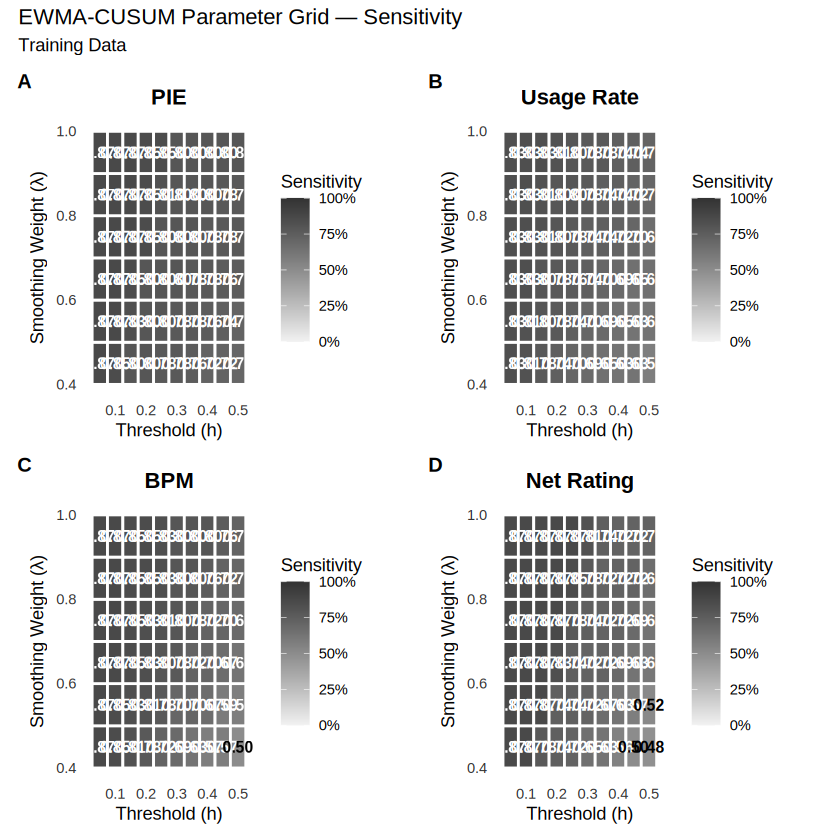

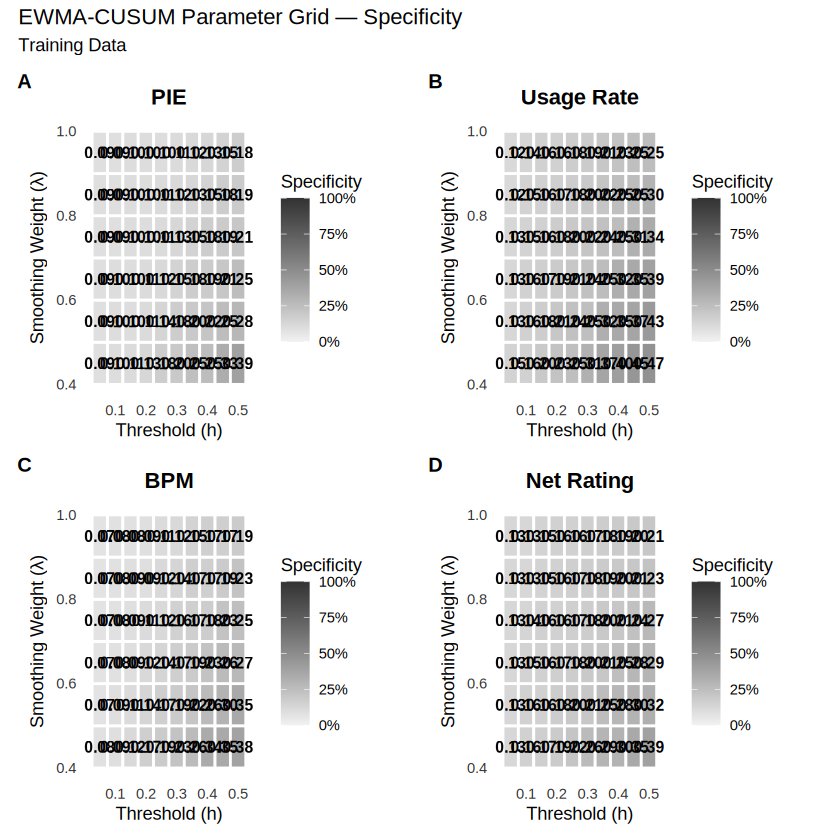

In [30]:
metric_labels <- c(
  "PIE"        = "PIE",
  "Usage_Rate" = "Usage Rate",
  "BPM"        = "BPM",
  "NetRtg"     = "Net Rating"
)

panel_tags <- c("A", "B", "C", "D")

# One heatmap panel; optionally restricted to a single injury area
make_heatmap_grey <- function(metric_name, perf_metric, data, inj_type = NULL,
                              fill_low = "grey95", fill_high = "grey20") {

  df <- data |> filter(metric == .env$metric_name)
  if (!is.null(inj_type)) df <- df |> filter(injury_type == .env$inj_type)

  # Switch label colour so text stays legible on light and dark tiles
  df <- df |> mutate(text_color = if_else(.data[[perf_metric]] > 0.55, "white", "black"))

  ggplot(df, aes(x = threshold, y = lambda, fill = .data[[perf_metric]])) +
    geom_tile(color = "white", linewidth = 0.8) +
    geom_text(
      aes(label = sprintf("%.2f", .data[[perf_metric]]), color = text_color),
      fontface = "bold", size = 3.3
    ) +
    scale_color_identity() +
    scale_fill_gradient(
      low      = fill_low,
      high     = fill_high,
      limits   = c(0, 1),
      na.value = "grey80",
      name     = perf_metric,
      labels   = scales::percent_format(accuracy = 1)
    ) +
    labs(
      title = metric_labels[metric_name],
      x     = "Threshold (h)",
      y     = "Smoothing Weight (λ)"
    ) +
    theme_minimal(base_size = 11) +
    theme(
      plot.title      = element_text(face = "bold", hjust = 0.5),
      axis.text.x     = element_text(color = "grey20"),
      axis.text.y     = element_text(color = "grey20"),
      panel.grid      = element_blank(),
      legend.position = "right"
    )
}

# 2x2 patchwork grid (one panel per metric) for one performance measure
make_grid_grey <- function(perf_metric, data, title, subtitle = "Training Data",
                           inj_type = NULL) {

  plots <- imap(metric_labels, function(label, m) {
    make_heatmap_grey(m, perf_metric, data, inj_type = inj_type)
  })

  (plots[[1]] | plots[[2]]) /
  (plots[[3]] | plots[[4]]) +
    plot_annotation(
      title      = title,
      subtitle   = subtitle,
      tag_levels = list(panel_tags)
    ) &
    theme(plot.tag = element_text(face = "bold", size = 12))
}

grid_sensitivity_grey <- make_grid_grey(
  "Sensitivity", confusion_summary_train_individualized,
  title = "EWMA-CUSUM Parameter Grid — Sensitivity"
)

grid_specificity_grey <- make_grid_grey(
  "Specificity", confusion_summary_train_individualized,
  title = "EWMA-CUSUM Parameter Grid — Specificity"
)

ggsave("heatmap_overall_sensitivity_greyscale.png", grid_sensitivity_grey,
       width = 12, height = 9, dpi = 300, bg = "white")
ggsave("heatmap_overall_specificity_greyscale.png", grid_specificity_grey,
       width = 12, height = 9, dpi = 300, bg = "white")

print(grid_sensitivity_grey)
print(grid_specificity_grey)

### Step 28. Heatmaps stratified by injury area
Same confusion-matrix logic, keeping `injury_type` in the final grouping. Figures are produced for upper-extremity, lower-extremity and core injuries.

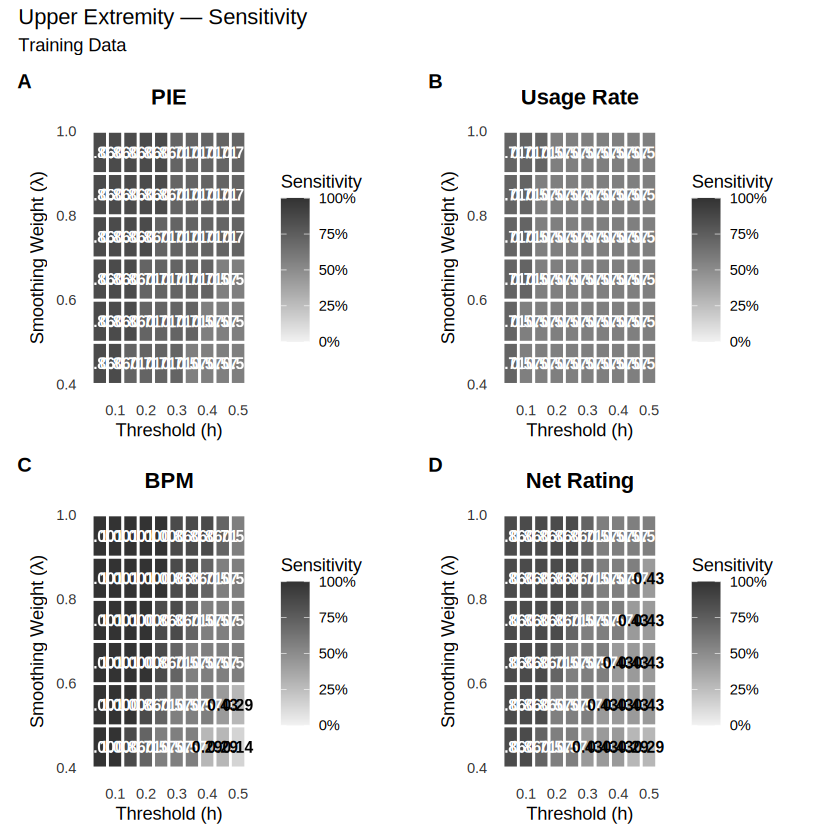

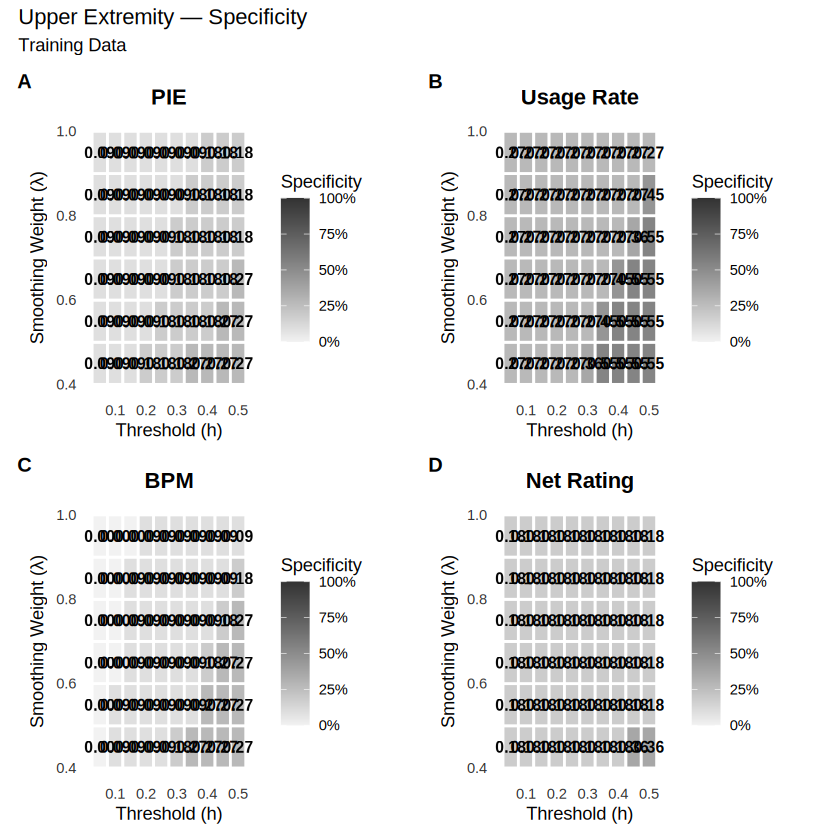

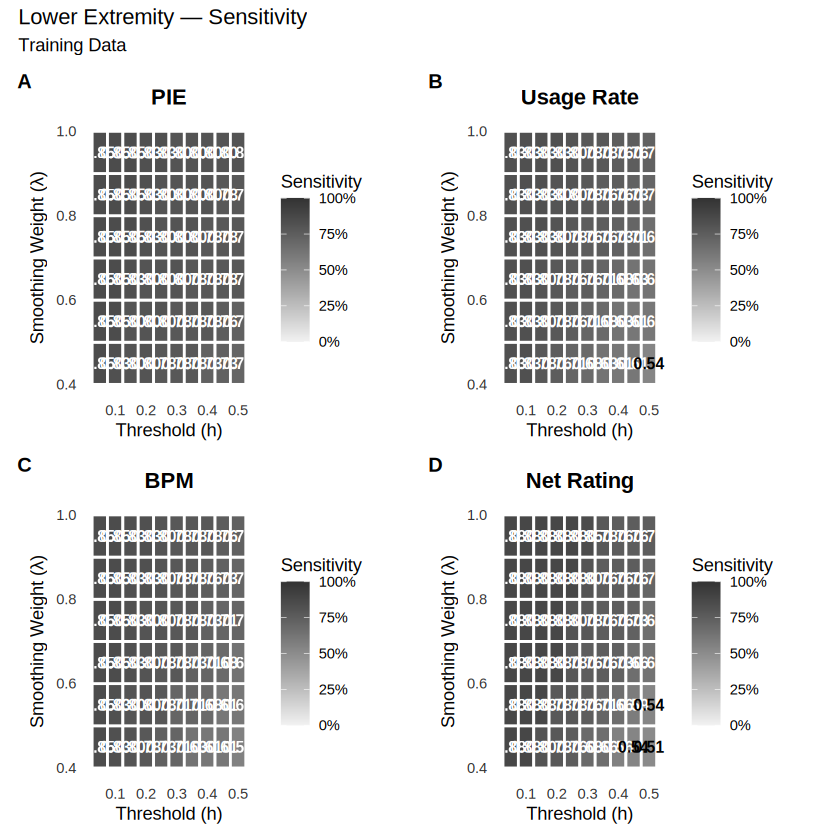

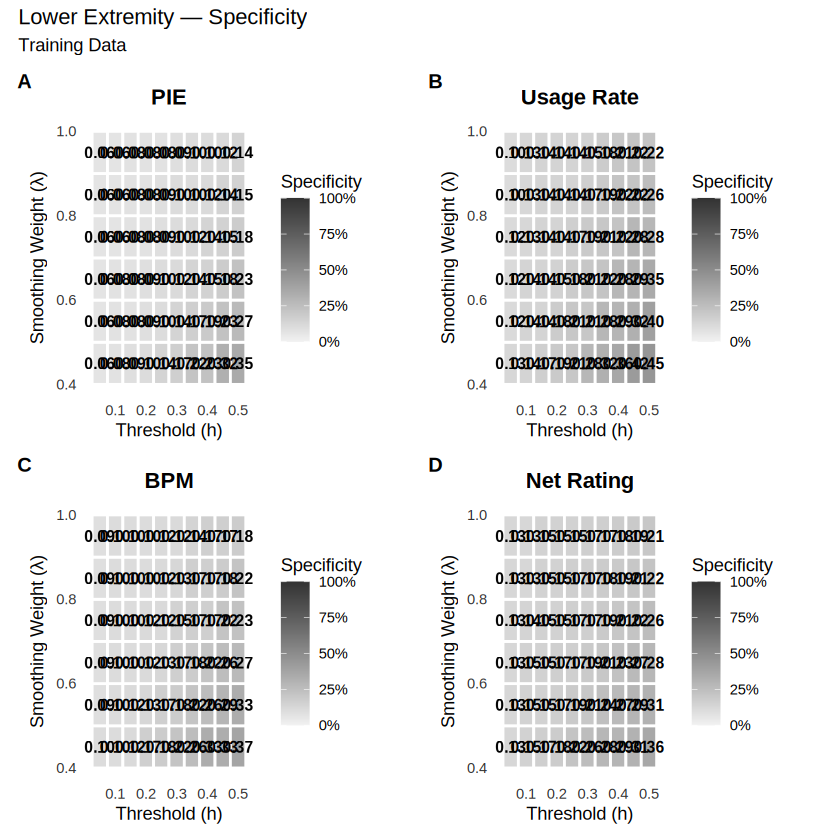

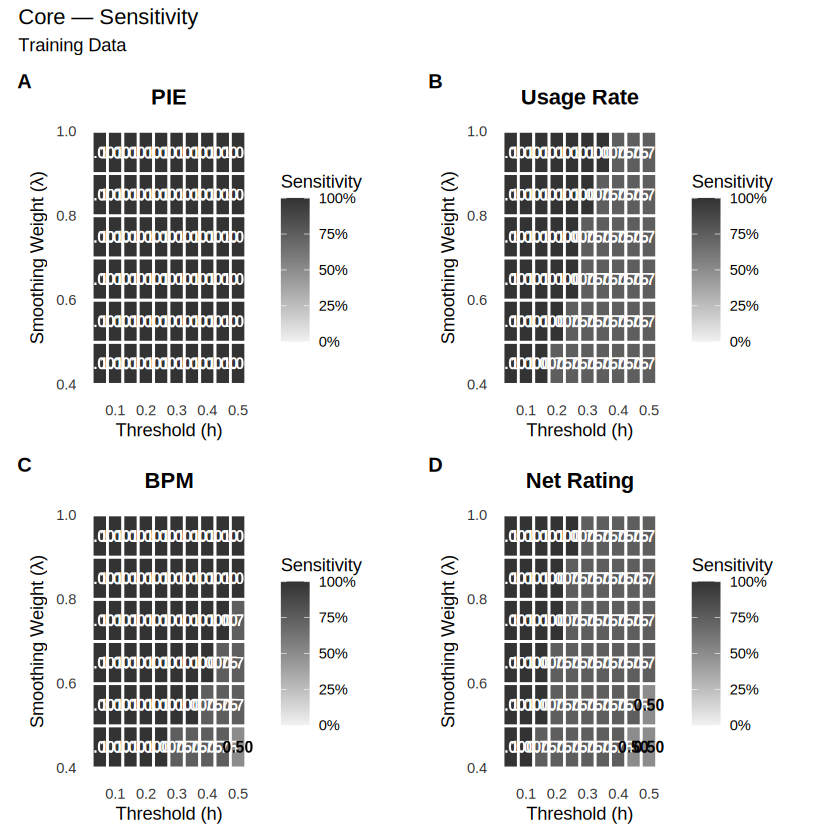

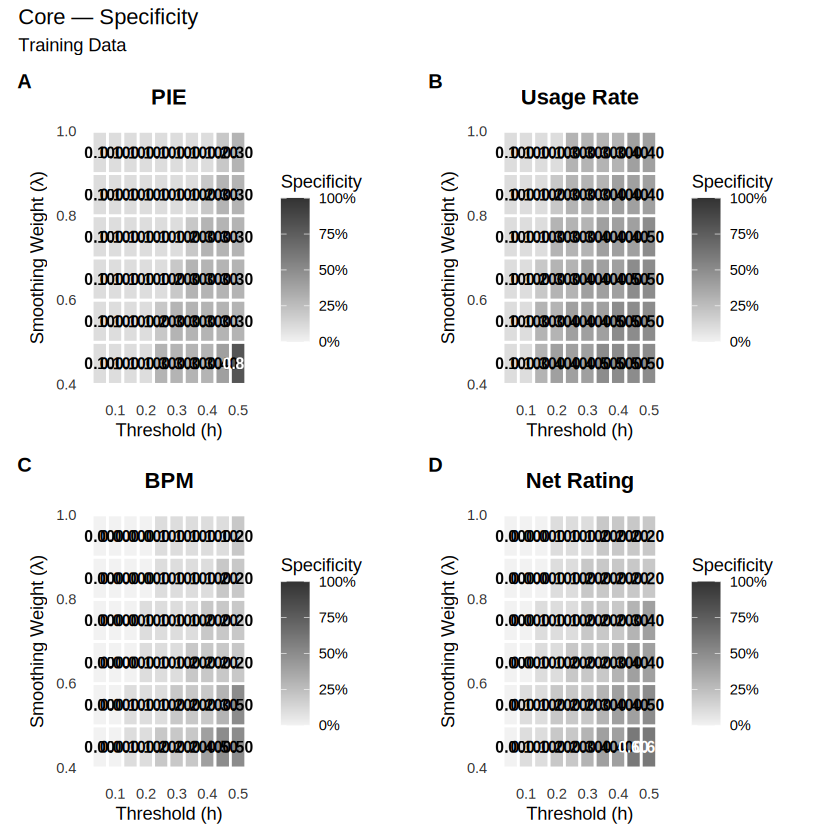

In [31]:
confusion_summary_train_individualized_by_type <-
  summarise_confusion(ewma_train_individualized, by = "injury_type") |>
  filter(injury_type %in% c("Upper Extremity", "Lower Extremity", "Core", "Other"))

injury_areas <- c("Upper Extremity", "Lower Extremity", "Core")

injury_type_grids <- map(injury_areas, function(inj_type) {

  grid_sensitivity <- make_grid_grey(
    "Sensitivity", confusion_summary_train_individualized_by_type,
    title = paste0(inj_type, " — Sensitivity"), inj_type = inj_type
  )
  grid_specificity <- make_grid_grey(
    "Specificity", confusion_summary_train_individualized_by_type,
    title = paste0(inj_type, " — Specificity"), inj_type = inj_type
  )

  inj_slug <- str_replace_all(str_to_lower(inj_type), " ", "_")

  ggsave(paste0("heatmap_", inj_slug, "_sensitivity_greyscale.png"),
         grid_sensitivity, width = 12, height = 9, dpi = 300, bg = "white")
  ggsave(paste0("heatmap_", inj_slug, "_specificity_greyscale.png"),
         grid_specificity, width = 12, height = 9, dpi = 300, bg = "white")

  list(sensitivity = grid_sensitivity, specificity = grid_specificity)
}) |>
  set_names(injury_areas)

# Six figures: 3 injury areas x 2 performance measures
walk(injury_type_grids, function(pair) {
  print(pair$sensitivity)
  print(pair$specificity)
})

### Step 29. Example control chart (held-out season)

Candidate true positives (signal fired and player was re-injured) under each metric's selected (λ, h), ranked by how close the lead time from first signal to re-injury is to 10 games. The example shown is Deni Avdija (`athlete_id` 4683021), Usage Rate.

In [32]:
selected_grid_by_metric <- selected_params_individualized |>
  split(~ metric)

ewma_test_selected <- map_dfr(names(selected_grid_by_metric), function(m) {
  run_chart_metric_individualized(
    m, player_baselines_frozen, test_season_code,
    grid = selected_grid_by_metric[[m]] |> select(lambda, threshold)
  )
})

candidate_true_positives <- summarise_true_positive_lead_time(ewma_test_selected) |>
  mutate(gap_from_target = abs(games_signal_to_reinjury - 10)) |>
  arrange(gap_from_target, desc(total_games))

candidate_true_positives |> print(n = 15)

# A tibble: 47 × 10
   athlete_id athlete_display_name metric     lambda threshold total_games
   <chr>      <chr>                <chr>       <dbl>     <dbl>       <int>
 1 3134932    John Konchar         PIE          0.45      0.5           11
 2 4017844    Guerschon Yabusele   BPM          0.45      0.45          10
 3 4017844    Guerschon Yabusele   PIE          0.45      0.5           10
 4 3134932    John Konchar         BPM          0.45      0.45          11
 5 3134932    John Konchar         Usage_Rate   0.45      0.45          11
 6 4594326    Kris Murray          PIE          0.45      0.5            9
 7 4594326    Kris Murray          Usage_Rate   0.45      0.45           9
 8 4594326    Kris Murray          BPM          0.45      0.45           9
 9 3064230    Cameron Payne        Usage_Rate   0.45      0.45           7
10 4683021    Deni Avdija          PIE          0.45      0.5           10
11 4683021    Deni Avdija          Usage_Rate   0.45      0.45          10
12 30

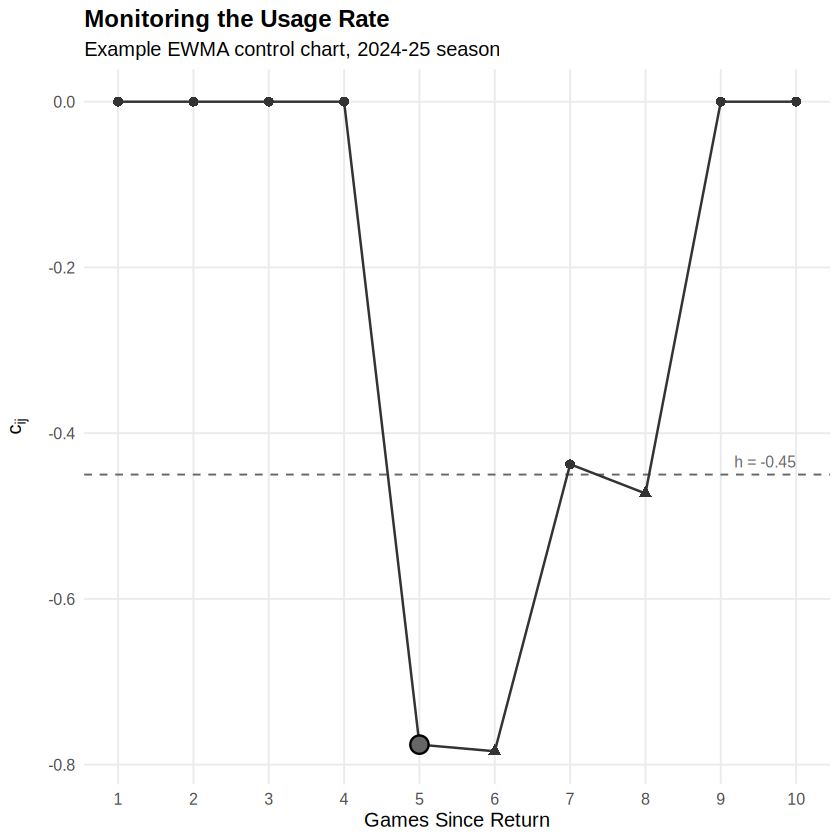

In [33]:
chosen_athlete_id <- "4683021"   # Deni Avdija
chosen_metric     <- "Usage_Rate"

chart_data <- ewma_test_selected |>
  filter(athlete_id == chosen_athlete_id, metric == chosen_metric)

chosen_h         <- selected_grid_by_metric[[chosen_metric]]$threshold[1]
first_signal_idx <- chart_data |> filter(signal) |> slice(1)

example_chart <- ggplot(chart_data, aes(x = game_index, y = ewma_stat)) +
  geom_hline(yintercept = -abs(chosen_h), linetype = "dashed", color = "grey40") +
  geom_line(color = "grey20", linewidth = 0.7) +
  geom_point(aes(shape = signal), size = 2.4, color = "grey20") +
  geom_point(data = first_signal_idx, aes(x = game_index, y = ewma_stat),
             shape = 21, size = 4.5, fill = "grey40", color = "black", stroke = 1) +
  annotate("text", x = max(chart_data$game_index), y = -abs(chosen_h),
           label = paste0("h = ", -abs(chosen_h)), vjust = -0.6, hjust = 1,
           size = 3.3, color = "grey40") +
  scale_shape_manual(values = c(`TRUE` = 17, `FALSE` = 16), guide = "none") +
  scale_x_continuous(breaks = seq(1, max(chart_data$game_index), by = 1)) +
  labs(
    title    = paste0("Monitoring the ", metric_labels[chosen_metric]),
    subtitle = paste0("Example EWMA control chart, ", test_season_label, " season"),
    x = "Games Since Return", y = expression(c[ij])
  ) +
  theme_minimal(base_size = 12) +
  theme(plot.title = element_text(face = "bold"), panel.grid.minor = element_blank())

ggsave("example_control_chart_avdija_usage_rate.png", example_chart,
       width = 8, height = 5, dpi = 300, bg = "white")

example_chart

## Part 6 — Descriptive and supplementary statistics

### Step 30. Games missed in qualifying stints (mean and 95% CI)
One row per athlete-season (the first qualifying stint), i.e. the analysis unit used throughout.

In [34]:
games_missed_ci <- t.test(qualifying_with_next_injury$actual_games_missed)

games_missed_summary <- tibble(
  n        = nrow(qualifying_with_next_injury),
  mean     = unname(games_missed_ci$estimate),
  ci_lower = games_missed_ci$conf.int[1],
  ci_upper = games_missed_ci$conf.int[2],
  sd       = sd(qualifying_with_next_injury$actual_games_missed)
)

games_missed_summary

n,mean,ci_lower,ci_upper,sd
<int>,<dbl>,<dbl>,<dbl>,<dbl>
209,5.894737,5.344237,6.445237,4.0369


### Step 31. Lead time from first signal to re-injury (true positives)
Held-out season, selected (λ, h).

In [35]:
tp_lead_time <- summarise_true_positive_lead_time(ewma_test_individualized)

tp_lead_time

tp_lead_time_summary <- tp_lead_time |>
  summarise(
    n      = n(),
    mean   = mean(games_signal_to_reinjury),
    sd     = sd(games_signal_to_reinjury),
    median = median(games_signal_to_reinjury),
    min    = min(games_signal_to_reinjury),
    max    = max(games_signal_to_reinjury),
    q1     = unname(quantile(games_signal_to_reinjury, 0.25)),
    q3     = unname(quantile(games_signal_to_reinjury, 0.75))
  )

tp_lead_time_summary

tp_lead_time_by_metric <- tp_lead_time |>
  group_by(metric) |>
  summarise(
    n      = n(),
    mean   = mean(games_signal_to_reinjury),
    sd     = sd(games_signal_to_reinjury),
    median = median(games_signal_to_reinjury),
    .groups = "drop"
  )

tp_lead_time_by_metric

athlete_id,athlete_display_name,metric,lambda,threshold,total_games,any_signal,first_signal_game,games_signal_to_reinjury
<chr>,<chr>,<chr>,<dbl>,<dbl>,<int>,<lgl>,<dbl>,<dbl>
2991070,Jerami Grant,PIE,0.45,0.50,6,TRUE,4,3
2991070,Jerami Grant,Usage_Rate,0.45,0.45,6,TRUE,1,6
3064230,Cameron Payne,BPM,0.45,0.45,7,TRUE,2,6
3064230,Cameron Payne,NetRtg,0.45,0.50,7,TRUE,2,6
3064230,Cameron Payne,PIE,0.45,0.50,7,TRUE,2,6
3064230,Cameron Payne,Usage_Rate,0.45,0.45,7,TRUE,1,7
3074752,Terry Rozier,BPM,0.45,0.45,8,TRUE,6,3
3074752,Terry Rozier,Usage_Rate,0.45,0.45,8,TRUE,6,3
3134932,John Konchar,BPM,0.45,0.45,11,TRUE,1,11


n,mean,sd,median,min,max,q1,q3
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
47,5.978723,4.386191,5,1,18,3,7


metric,n,mean,sd,median
<chr>,<int>,<dbl>,<dbl>,<dbl>
BPM,12,6.333333,4.716187,5.0
NetRtg,8,5.750000,4.803273,5.0
PIE,13,6.000000,4.527693,5.0
Usage_Rate,14,5.785714,4.209487,4.5


### Step 32. 95% CIs with Sandwich SEs for sensitivity, specificity and accuracy at the selected (λ, h)
Training seasons.

In [36]:
## ============================================================
## 95% CIs FOR SENSITIVITY / SPECIFICITY / ACCURACY AT THE
## SELECTED (lambda, h), WITH ATHLETE-CLUSTERED (SANDWICH) SEs
## ============================================================

# Cluster-robust (sandwich) SE for a proportion, clustered on `cluster`
cluster_robust_prop <- function(y, cluster, conf = 0.95) {
  keep    <- !is.na(y)
  y       <- as.numeric(y[keep])
  cluster <- cluster[keep]

  n   <- length(y)
  p   <- mean(y)
  e_g <- tapply(y - p, cluster, sum)    # residuals summed within athlete
  G   <- length(e_g)

  se_naive   <- sqrt(p * (1 - p) / n)
  se_cluster <- sqrt(G / (G - 1) * sum(e_g^2) / n^2)
  z          <- qnorm(1 - (1 - conf) / 2)

  tibble(
    estimate      = p,
    n_stints      = n,
    n_athletes    = G,
    se_naive      = se_naive,
    se_cluster    = se_cluster,
    design_effect = (se_cluster / se_naive)^2,
    naive_lower   = p - z * se_naive,
    naive_upper   = p + z * se_naive,
    cluster_lower = p - z * se_cluster,
    cluster_upper = p + z * se_cluster
  )
}

# Stint-level classification at each metric's selected (lambda, threshold)
stint_predictions <- function(ewma_df, selected_params) {
  ewma_df |>
    semi_join(selected_params, by = c("metric", "lambda", "threshold")) |>
    group_by(athlete_id, Season, Injury_Stint, had_second_injury,
             metric, lambda, threshold) |>
    summarise(predicted_positive = any(signal, na.rm = TRUE), .groups = "drop")
}

clustered_performance_ci <- function(stints) {
  stints |>
    group_by(metric, lambda, threshold) |>
    group_modify(function(d, key) {
      pos <- d |> filter(had_second_injury)
      neg <- d |> filter(!had_second_injury)
      bind_rows(
        Sensitivity = cluster_robust_prop(pos$predicted_positive,  pos$athlete_id),
        Specificity = cluster_robust_prop(!neg$predicted_positive, neg$athlete_id),
        Accuracy    = cluster_robust_prop(d$predicted_positive == d$had_second_injury,
                                          d$athlete_id),
        .id = "measure"
      )
    }) |>
    ungroup()
}

stints_train_selected <- stint_predictions(ewma_train_individualized, selected_params_individualized)
stints_test_selected  <- stint_predictions(ewma_test_individualized,  selected_params_individualized)

performance_ci_clustered <- bind_rows(
  train    = clustered_performance_ci(stints_train_selected),
  held_out = clustered_performance_ci(stints_test_selected),
  .id = "split"
)

performance_ci_clustered |>
  select(split, metric, lambda, threshold, measure, estimate, n_stints, n_athletes,
         se_naive, se_cluster, design_effect, cluster_lower, cluster_upper) |>
  print(n = Inf, width = Inf)

# A tibble: 24 × 13
   split    metric     lambda threshold measure     estimate n_stints n_athletes
   <chr>    <chr>       <dbl>     <dbl> <chr>          <dbl>    <int>      <int>
 1 train    BPM          0.45      0.45 Sensitivity    0.574       54         45
 2 train    BPM          0.45      0.45 Specificity    0.353      102         94
 3 train    BPM          0.45      0.45 Accuracy       0.429      156        131
 4 train    NetRtg       0.45      0.5  Sensitivity    0.481       54         45
 5 train    NetRtg       0.45      0.5  Specificity    0.392      102         94
 6 train    NetRtg       0.45      0.5  Accuracy       0.423      156        131
 7 train    PIE          0.45      0.5  Sensitivity    0.704       54         45
 8 train    PIE          0.45      0.5  Specificity    0.392      102         94
 9 train    PIE          0.45      0.5  Accuracy       0.5        156        131
10 train    Usage_Rate   0.45      0.45 Sensitivity    0.630       54         45
11 train

In [52]:
## ============================================================
## TABLES 1 AND 2: POINT ESTIMATE (95% CI), CLUSTERED SEs
## ============================================================

format_performance_table <- function(ci_table, which_split) {
  ci_table |>
    filter(split == which_split) |>
    mutate(
      Metric    = recode(metric, BPM = "BPM", NetRtg = "Net Rating",
                         PIE = "PIE", Usage_Rate = "Usage Rate"),
      lambda    = sprintf("%.2f", lambda),
      threshold = sprintf("%.2f", threshold),
      cell      = sprintf("%.1f (%.1f, %.1f)",
                          100 * estimate, 100 * cluster_lower, 100 * cluster_upper),
      measure   = paste0(measure, ", % (95% CI)")
    ) |>
    select(Metric, lambda, `|h|` = threshold, measure, cell) |>
    pivot_wider(names_from = measure, values_from = cell) |>
    select(Metric, lambda, `|h|`,
           `Sensitivity, % (95% CI)`, `Specificity, % (95% CI)`, `Accuracy, % (95% CI)`) |>
    arrange(Metric)
}

table1_train    <- format_performance_table(performance_ci_clustered, "train")
table2_held_out <- format_performance_table(performance_ci_clustered, "held_out")

table1_train
table2_held_out

# Optional: CSVs to paste into Word
write_csv(table1_train,    "table1_training_seasons.csv")
write_csv(table2_held_out, "table2_holdout_season.csv")

Metric,lambda,|h|,"Sensitivity, % (95% CI)","Specificity, % (95% CI)","Accuracy, % (95% CI)"
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
BPM,0.45,0.45,"57.4 (44.0, 70.9)","35.3 (25.8, 44.8)","42.9 (34.8, 51.1)"
Net Rating,0.45,0.50,"48.1 (34.6, 61.6)","39.2 (29.8, 48.7)","42.3 (34.7, 49.9)"
PIE,0.45,0.50,"70.4 (58.7, 82.0)","39.2 (29.7, 48.8)","50.0 (42.1, 57.9)"
Usage Rate,0.45,0.45,"63.0 (48.8, 77.1)","45.1 (35.0, 55.2)","51.3 (42.9, 59.7)"


Metric,lambda,|h|,"Sensitivity, % (95% CI)","Specificity, % (95% CI)","Accuracy, % (95% CI)"
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
BPM,0.45,0.45,"66.7 (44.3, 89.1)","22.9 (8.7, 37.0)","37.7 (24.6, 50.9)"
Net Rating,0.45,0.50,"44.4 (20.8, 68.1)","37.1 (20.9, 53.4)","39.6 (26.3, 52.9)"
PIE,0.45,0.50,"72.2 (50.9, 93.5)","25.7 (11.0, 40.4)","41.5 (28.1, 54.9)"
Usage Rate,0.45,0.45,"77.8 (58.0, 97.5)","34.3 (18.3, 50.2)","49.1 (35.5, 62.6)"


### Step 33. Highest-accuracy point on the wide grid (training seasons)
On the wide grid, the highest-accuracy settings are near-trivial classifiers (specificity ≈ 1, sensitivity ≈ 0), which is why (λ, h) selection uses the narrower Step 16 grid and why the ROC/AUC comparison is reported.

In [40]:
confusion_summary_train_wide |>
  group_by(metric) |>
  slice_max(Accuracy, n = 1, with_ties = FALSE) |>
  ungroup()

metric,lambda,threshold,TP,FP,TN,FN,Sensitivity,Specificity,PPV,NPV,Accuracy
<chr>,<dbl>,<dbl>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
BPM,0.45,2.25,1,0,102,53,0.01851852,1.0000000,1.0000000,0.6580645,0.6602564
NetRtg,0.45,2.00,3,2,100,51,0.05555556,0.9803922,0.6000000,0.6622517,0.6602564
PIE,0.85,2.50,2,1,101,52,0.03703704,0.9901961,0.6666667,0.6601307,0.6602564
Usage_Rate,0.45,3.00,0,0,102,54,0.00000000,1.0000000,NaN,0.6538462,0.6538462


### Step 34. Games from return to re-injury (all re-injured players)
Independent of chart signal, metric, (λ, h) and train/test split.

In [41]:
games_until_reinjury <- qualifying_with_next_injury |>
  filter(had_second_injury == TRUE) |>
  left_join(
    game_by_game |>
      group_by(athlete_id, Season, Injury_Stint) |>
      summarise(games_until_reinjury = max(games_since_return), .groups = "drop"),
    by = c("athlete_id", "Season", "Injury_Stint")
  )

games_until_reinjury_summary <- games_until_reinjury |>
  summarise(
    n      = sum(!is.na(games_until_reinjury)),
    mean   = mean(games_until_reinjury, na.rm = TRUE),
    sd     = sd(games_until_reinjury, na.rm = TRUE),
    median = median(games_until_reinjury, na.rm = TRUE),
    min    = min(games_until_reinjury, na.rm = TRUE),
    max    = max(games_until_reinjury, na.rm = TRUE),
    q1     = unname(quantile(games_until_reinjury, 0.25, na.rm = TRUE)),
    q3     = unname(quantile(games_until_reinjury, 0.75, na.rm = TRUE))
  ) |>
  mutate(
    CIL = mean - qt(0.975, df = n - 1) * sd / sqrt(n),
    CIU = mean + qt(0.975, df = n - 1) * sd / sqrt(n)
  )

games_until_reinjury_summary

## ============================================================
## CLUSTER-ROBUST (SANDWICH) CI FOR A MEAN, CLUSTERED ON ATHLETE
## ============================================================

cluster_robust_mean <- function(y, cluster, conf = 0.95) {
  keep    <- !is.na(y)
  y       <- y[keep]
  cluster <- cluster[keep]

  n   <- length(y)
  m   <- mean(y)
  e_g <- tapply(y - m, cluster, sum)    # residuals summed within athlete
  G   <- length(e_g)

  se_naive   <- sd(y) / sqrt(n)                      # same SE as t.test()
  se_cluster <- sqrt(G / (G - 1) * sum(e_g^2) / n^2) # = sandwich::vcovCL on lm(y ~ 1)
  t_crit     <- qt(1 - (1 - conf) / 2, df = G - 1)   # df = clusters - 1

  tibble(
    n_stints      = n,
    n_athletes    = G,
    mean          = m,
    sd            = sd(y),
    se_naive      = se_naive,
    se_cluster    = se_cluster,
    design_effect = (se_cluster / se_naive)^2,
    cluster_lower = m - t_crit * se_cluster,
    cluster_upper = m + t_crit * se_cluster
  )
}

# Games missed in the qualifying stint (all 209 stints)
games_missed_ci_clustered <- cluster_robust_mean(
  qualifying_with_next_injury$actual_games_missed,
  qualifying_with_next_injury$athlete_id
)
games_missed_ci_clustered

# Games from return to re-injury (re-injured stints only)
games_until_reinjury_ci_clustered <- cluster_robust_mean(
  games_until_reinjury$games_until_reinjury,
  games_until_reinjury$athlete_id
)
games_until_reinjury_ci_clustered

n,mean,sd,median,min,max,q1,q3,CIL,CIU
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
72,15.86111,12.94986,12.5,1,51,5.75,22.25,12.81804,18.90418


n_stints,n_athletes,mean,sd,se_naive,se_cluster,design_effect,cluster_lower,cluster_upper
<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
209,170,5.894737,4.0369,0.2792382,0.2869405,1.055927,5.328287,6.461186


n_stints,n_athletes,mean,sd,se_naive,se_cluster,design_effect,cluster_lower,cluster_upper
<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
72,60,15.86111,12.94986,1.526155,1.655163,1.176208,12.54914,19.17308


### Step 35. Players with a qualifying stint, by season

In [42]:
qualifying_with_next_injury |>
  distinct(Season, athlete_id) |>
  count(Season)

Season,n
<dbl>,<int>
2021,58
2022,31
2023,29
2024,38
2025,53


### Step 37. Post-return mean metric values: re-injured vs. not re-injured
Per-stint mean of each metric over the post-return window, compared with Welch two-sample t-tests.

In [43]:
player_mean_metrics <- game_by_game |>
  left_join(
    qualifying_with_next_injury |>
      select(athlete_id, Season, Injury_Stint, had_second_injury),
    by = c("athlete_id", "Season", "Injury_Stint")
  ) |>
  group_by(athlete_id, athlete_display_name, Season, Injury_Stint, had_second_injury) |>
  summarise(
    across(all_of(metrics_to_model), \(x) mean(x, na.rm = TRUE)),
    .groups = "drop"
  )

player_mean_metrics |>
  group_by(had_second_injury) |>
  summarise(
    Mean_PIE = mean(PIE,        na.rm = TRUE),
    Mean_UR  = mean(Usage_Rate, na.rm = TRUE),
    Mean_BP  = mean(BPM,        na.rm = TRUE),
    Mean_NR  = mean(NetRtg,     na.rm = TRUE),
    n        = n()
  )

metric_ttests <- map_dfr(metrics_to_model, function(m) {
  result <- t.test(player_mean_metrics[[m]] ~ player_mean_metrics$had_second_injury)

  tibble(
    metric         = m,
    mean_not_reinj = result$estimate[1],
    mean_reinj     = result$estimate[2],
    mean_diff      = result$estimate[1] - result$estimate[2],
    ci_lower       = result$conf.int[1],
    ci_upper       = result$conf.int[2],
    t_stat         = result$statistic,
    df             = result$parameter,
    p_value        = result$p.value
  )
})

metric_ttests

had_second_injury,Mean_PIE,Mean_UR,Mean_BP,Mean_NR,n
<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<int>
FALSE,0.1138481,0.1089788,0.3090656,-4.426902,137
TRUE,0.1398882,0.1316229,0.8796261,-1.882598,72


metric,mean_not_reinj,mean_reinj,mean_diff,ci_lower,ci_upper,t_stat,df,p_value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
PIE,0.1138481,0.1398882,-0.02604004,-0.04461889,-0.007461187,-2.7692864,150.8977,0.006323275
Usage_Rate,0.1089788,0.1316229,-0.02264410,-0.03923418,-0.006054021,-2.6966882,151.8055,0.007794691
BPM,0.3090656,0.8796261,-0.57056055,-1.78088258,0.639761484,-0.9302434,178.9088,0.353498541
NetRtg,-4.4269019,-1.8825983,-2.54430362,-8.02261827,2.934011043,-0.9170502,163.6760,0.360465615


### Step 37. Pre- vs. post-injury panel
One row per stint with the player's mean pre-injury value (`<metric>_pre`, Step 17 panel), mean post-return value (`<metric>_post`, Step 36) and change (`<metric>_diff = post - pre`). Stints with no pre-injury games in that season are excluded.

In [44]:
pre_injury_means <- pre_injury_panel |>
  group_by(athlete_id, Season, Injury_Stint) |>
  summarise(
    across(all_of(metrics_to_model), \(x) mean(x, na.rm = TRUE), .names = "{.col}_pre"),
    .groups = "drop"
  )

player_pre_post <- player_mean_metrics |>
  rename_with(\(x) paste0(x, "_post"), all_of(metrics_to_model)) |>
  inner_join(pre_injury_means, by = c("athlete_id", "Season", "Injury_Stint"))

for (m in metrics_to_model) {
  player_pre_post[[paste0(m, "_diff")]] <-
    player_pre_post[[paste0(m, "_post")]] - player_pre_post[[paste0(m, "_pre")]]
}

player_pre_post |> count(had_second_injury)

had_second_injury,n
<lgl>,<int>
FALSE,126
TRUE,66


### Step 38. Difference-in-differences: Welch t-tests and Cohen's *d*
Compares each stint's (post − pre) change between re-injured and not re-injured players; *d* uses the pooled SD of the change scores.

In [45]:
did_ttests <- map_dfr(metrics_to_model, function(m) {
  diff_col <- paste0(m, "_diff")

  group0 <- player_pre_post[[diff_col]][player_pre_post$had_second_injury == FALSE]
  group1 <- player_pre_post[[diff_col]][player_pre_post$had_second_injury == TRUE]

  result <- t.test(player_pre_post[[diff_col]] ~ player_pre_post$had_second_injury)

  n0  <- sum(!is.na(group0)); n1 <- sum(!is.na(group1))
  sd0 <- sd(group0, na.rm = TRUE); sd1 <- sd(group1, na.rm = TRUE)
  pooled_sd <- sqrt(((n0 - 1) * sd0^2 + (n1 - 1) * sd1^2) / (n0 + n1 - 2))
  cohens_d  <- (mean(group0, na.rm = TRUE) - mean(group1, na.rm = TRUE)) / pooled_sd

  tibble(
    metric              = m,
    n_not_reinj         = n0,
    n_reinj             = n1,
    mean_diff_not_reinj = result$estimate[1],
    mean_diff_reinj     = result$estimate[2],
    did_estimate        = result$estimate[1] - result$estimate[2],
    ci_lower            = result$conf.int[1],
    ci_upper            = result$conf.int[2],
    t_stat              = result$statistic,
    df                  = result$parameter,
    p_value             = result$p.value,
    cohens_d            = cohens_d
  )
})

did_ttests

metric,n_not_reinj,n_reinj,mean_diff_not_reinj,mean_diff_reinj,did_estimate,ci_lower,ci_upper,t_stat,df,p_value,cohens_d
<chr>,<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
PIE,126,66,0.01199553,0.007850322,0.004145207,-0.011601588,0.01989200,0.5208698,127.9529,0.6033577,0.08005411
Usage_Rate,126,66,0.01100522,0.008486337,0.002518884,-0.006480916,0.01151868,0.5533678,139.2610,0.5808989,0.08250194
BPM,126,66,0.55363505,0.302642011,0.250993036,-1.052621455,1.55460753,0.3806117,141.8294,0.7040609,0.05637350
NetRtg,125,66,2.03391781,0.357520819,1.676396987,-4.219555762,7.57234974,0.5618877,147.4738,0.5750455,0.08225621


### Step 39. Nonparametric tests
**Wilcoxon rank-sum (Mann–Whitney):** the (post − pre) change compared between independent groups (re-injured vs. not), with the Hodges–Lehmann estimate of the location shift.

**Wilcoxon signed-rank (paired, within group):** post- vs. pre-injury values for the same players, separately for each group.

In [46]:
did_wilcox <- map_dfr(metrics_to_model, function(m) {
  diff_col <- paste0(m, "_diff")
  result <- wilcox.test(
    player_pre_post[[diff_col]] ~ player_pre_post$had_second_injury,
    conf.int = TRUE
  )

  tibble(
    metric                = m,
    median_diff_not_reinj = median(player_pre_post[[diff_col]][player_pre_post$had_second_injury == FALSE], na.rm = TRUE),
    median_diff_reinj     = median(player_pre_post[[diff_col]][player_pre_post$had_second_injury == TRUE],  na.rm = TRUE),
    hl_estimate           = result$estimate,   # Hodges-Lehmann location shift
    ci_lower              = result$conf.int[1],
    ci_upper              = result$conf.int[2],
    W_stat                = result$statistic,
    p_value               = result$p.value
  )
})

did_wilcox

metric,median_diff_not_reinj,median_diff_reinj,hl_estimate,ci_lower,ci_upper,W_stat,p_value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
PIE,0.003742652,0.007467016,0.002102015,-0.012344449,0.01686635,4255,0.7918838
Usage_Rate,0.006919910,0.003430693,0.003117138,-0.005201568,0.01137050,4410,0.4916480
BPM,0.439317838,0.151872611,0.272882573,-0.828832447,1.45937454,4356,0.5891730
NetRtg,0.548374325,-0.032778691,0.582145285,-4.075891982,5.44214159,4209,0.8182268


In [47]:
signed_rank_within_group <- map_dfr(metrics_to_model, function(m) {
  pre_col  <- paste0(m, "_pre")
  post_col <- paste0(m, "_post")

  map_dfr(c(FALSE, TRUE), function(status) {
    sub    <- player_pre_post |> filter(had_second_injury == status)
    result <- wilcox.test(sub[[post_col]], sub[[pre_col]], paired = TRUE, conf.int = TRUE)

    tibble(
      metric            = m,
      had_second_injury = status,
      n                 = nrow(sub),
      median_pre        = median(sub[[pre_col]],  na.rm = TRUE),
      median_post       = median(sub[[post_col]], na.rm = TRUE),
      hl_estimate       = result$estimate,
      ci_lower          = result$conf.int[1],
      ci_upper          = result$conf.int[2],
      V_stat            = result$statistic,
      p_value           = result$p.value
    )
  })
})

signed_rank_within_group

metric,had_second_injury,n,median_pre,median_post,hl_estimate,ci_lower,ci_upper,V_stat,p_value
<chr>,<lgl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
PIE,FALSE,126,0.10310153,0.1164249,0.009703801,0.0012840708,0.01886973,4927,0.0241585416
PIE,TRUE,66,0.13033712,0.1430489,0.007732706,-0.0044930921,0.01974332,1303,0.2082283339
Usage_Rate,FALSE,126,0.09559299,0.1060125,0.009346153,0.0041685440,0.01491889,5460,0.0003818331
Usage_Rate,TRUE,66,0.11596615,0.1190027,0.006089987,-0.0004569895,0.01335096,1397,0.0630368281
BPM,FALSE,126,-0.01445150,0.6892999,0.574121729,-0.1392375001,1.26716763,4660,0.1086006944
BPM,TRUE,66,0.76804340,1.0139481,0.235544974,-0.6283752803,1.18965719,1207,0.5188000444
NetRtg,FALSE,126,-6.76286438,-4.6024753,1.528522637,-1.5095316126,4.61847040,4340,0.3219297287
NetRtg,TRUE,66,-1.29192892,-3.5764345,0.973139384,-2.7287627281,4.41193923,1178,0.6455579600


In [48]:
train_athletes <- qualifying_with_next_injury |>
  filter(Season %in% train_seasons) |> distinct(athlete_id) |> pull()

test_overlap <- qualifying_with_next_injury |>
  filter(Season == test_season_code) |>
  distinct(athlete_id) |>
  mutate(
    had_training_stint    = athlete_id %in% train_athletes,
    has_own_baseline      = athlete_id %in% player_baselines_train$athlete_id
  )

test_overlap |> count(had_training_stint, has_own_baseline)

had_training_stint,has_own_baseline,n
<lgl>,<lgl>,<int>
FALSE,FALSE,39
TRUE,FALSE,2
TRUE,TRUE,12


In [50]:
season_label <- function(s) paste0(s - 1, "-", substr(s, 3, 4))   # 2025 -> "2024-25"

## ---- Athletes, index injuries and games missed, by season ----
summarise_qualifying <- function(df) {
  df |>
    summarise(
      athletes            = n_distinct(athlete_id),
      index_injuries      = n(),
      games_missed_total  = sum(actual_games_missed),
      games_missed_mean   = round(mean(actual_games_missed), 1),
      dnp_games_total     = sum(games_missed_in_stint),
      subsequent_injuries = sum(had_second_injury)
    )
}

qualifying_by_season <- bind_rows(
  qualifying_with_next_injury |>
    group_by(Season) |> summarise_qualifying() |>
    mutate(Season = season_label(Season)),
  qualifying_with_next_injury |>
    summarise_qualifying() |> mutate(Season = "Total")
)
qualifying_by_season

## ---- Body region of the index injury, by season: n (%) ----
region_levels <- c("Lower Extremity", "Upper Extremity", "Core", "Head", "Other")

region_by_season <- qualifying_with_next_injury |>
  mutate(Season = season_label(Season)) |>
  bind_rows(qualifying_with_next_injury |> mutate(Season = "Total")) |>
  mutate(injury_type = factor(injury_type, levels = region_levels)) |>
  count(Season, injury_type, .drop = FALSE) |>
  group_by(Season) |>
  mutate(cell = sprintf("%d (%.1f%%)", n, 100 * n / sum(n))) |>
  ungroup() |>
  select(-n) |>
  pivot_wider(names_from = injury_type, values_from = cell)
region_by_season
qualifying_stints |> count(Season)

Season,athletes,index_injuries,games_missed_total,games_missed_mean,dnp_games_total,subsequent_injuries
<chr>,<int>,<int>,<int>,<dbl>,<int>,<int>
2020-21,58,58,353,6.1,243,19
2021-22,31,31,172,5.5,103,11
2022-23,29,29,144,5.0,79,10
2023-24,38,38,216,5.7,112,14
2024-25,53,53,347,6.5,217,18
Total,170,209,1232,5.9,754,72


Season,Lower Extremity,Upper Extremity,Core,Head,Other
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
2020-21,44 (75.9%),8 (13.8%),3 (5.2%),2 (3.4%),1 (1.7%)
2021-22,29 (93.5%),1 (3.2%),1 (3.2%),0 (0.0%),0 (0.0%)
2022-23,20 (69.0%),5 (17.2%),4 (13.8%),0 (0.0%),0 (0.0%)
2023-24,26 (68.4%),4 (10.5%),6 (15.8%),0 (0.0%),2 (5.3%)
2024-25,38 (71.7%),7 (13.2%),8 (15.1%),0 (0.0%),0 (0.0%)
Total,157 (75.1%),25 (12.0%),22 (10.5%),2 (1.0%),3 (1.4%)


Season,n
<dbl>,<int>
2021,67
2022,33
2023,31
2024,41
2025,61


In [51]:
## ============================================================
## OVERLAP BETWEEN TRAINING SEASONS AND THE HOLD-OUT SEASON
## ============================================================

train_athletes <- qualifying_with_next_injury |>
  filter(Season %in% train_seasons) |>
  distinct(athlete_id) |>
  pull()

test_overlap <- qualifying_with_next_injury |>
  filter(Season == test_season_code) |>
  distinct(athlete_id) |>
  mutate(
    had_training_stint = athlete_id %in% train_athletes,
    has_own_baseline   = athlete_id %in% player_baselines_train$athlete_id
  )

test_overlap |> count(had_training_stint, has_own_baseline)

had_training_stint,has_own_baseline,n
<lgl>,<lgl>,<int>
FALSE,FALSE,39
TRUE,FALSE,2
TRUE,TRUE,12


In [53]:
## ============================================================
## GAMES FROM RETURN TO SUBSEQUENT INJURY: MEAN AND 95% CI,
## CLUSTER-ROBUST (SANDWICH) SE CLUSTERED ON ATHLETE
## ============================================================

cluster_robust_mean <- function(y, cluster, conf = 0.95) {
  keep    <- !is.na(y)
  y       <- y[keep]
  cluster <- cluster[keep]

  n   <- length(y)
  m   <- mean(y)
  e_g <- tapply(y - m, cluster, sum)    # residuals summed within athlete
  G   <- length(e_g)

  se_naive   <- sd(y) / sqrt(n)
  se_cluster <- sqrt(G / (G - 1) * sum(e_g^2) / n^2)
  t_crit     <- qt(1 - (1 - conf) / 2, df = G - 1)

  tibble(
    n_stints      = n,
    n_athletes    = G,
    mean          = m,
    sd            = sd(y),
    se_naive      = se_naive,
    se_cluster    = se_cluster,
    design_effect = (se_cluster / se_naive)^2,
    cluster_lower = m - t_crit * se_cluster,
    cluster_upper = m + t_crit * se_cluster
  )
}

# Games played from return to the game before the subsequent injury
games_until_reinjury <- qualifying_with_next_injury |>
  filter(had_second_injury == TRUE) |>
  left_join(
    game_by_game |>
      group_by(athlete_id, Season, Injury_Stint) |>
      summarise(games_until_reinjury = max(games_since_return), .groups = "drop"),
    by = c("athlete_id", "Season", "Injury_Stint")
  )

games_until_reinjury_ci_clustered <- cluster_robust_mean(
  games_until_reinjury$games_until_reinjury,
  games_until_reinjury$athlete_id
)

games_until_reinjury_ci_clustered

n_stints,n_athletes,mean,sd,se_naive,se_cluster,design_effect,cluster_lower,cluster_upper
<int>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
72,60,15.86111,12.94986,1.526155,1.655163,1.176208,12.54914,19.17308


## Optional: export result tables
Set `export_tables <- TRUE` to write the main result tables to an Excel workbook (requires the `writexl` package).

In [ ]:
export_tables <- FALSE

if (export_tables) {
  if (!requireNamespace("writexl", quietly = TRUE)) install.packages("writexl")
  writexl::write_xlsx(
    list(
      "train_full_grid"             = confusion_summary_train_comparison,
      "autocorr_validation"         = autocorrelation_validation,
      "autocorr_validation_summary" = autocorrelation_validation_summary,
      "test_holdout_comparison"     = confusion_summary_test_comparison,
      "auc_summary"                 = auc_summary
    ),
    "reinjury_ewma_confusion_matrices.xlsx"
  )
}

## Session information

In [ ]:
sessionInfo()

R version 4.6.1 (2026-06-24)
Platform: x86_64-pc-linux-gnu
Running under: Ubuntu 24.04.5 LTS

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3 
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.26.so;  LAPACK version 3.12.0

locale:
 [1] LC_CTYPE=en_US.UTF-8       LC_NUMERIC=C              
 [3] LC_TIME=en_US.UTF-8        LC_COLLATE=en_US.UTF-8    
 [5] LC_MONETARY=en_US.UTF-8    LC_MESSAGES=en_US.UTF-8   
 [7] LC_PAPER=en_US.UTF-8       LC_NAME=C                 
 [9] LC_ADDRESS=C               LC_TELEPHONE=C            
[11] LC_MEASUREMENT=en_US.UTF-8 LC_IDENTIFICATION=C       

time zone: Etc/UTC
tzcode source: system (glibc)

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] patchwork_1.3.2 hoopR_3.1.0     lubridate_1.9.5 forcats_1.0.1  
 [5] stringr_1.6.0   dplyr_1.2.1     purrr_1.2.2     readr_2.2.0    
 [9] tidyr_1.3.2     tibble_3.3.1    ggpl